# Agri Predictive Analytics Model: Yield Forecasting at 31 August

**Fictional client:** Nagpur agritech startup | **Region:** Vidarbha (Nagpur, Wardha, Amravati, Yavatmal, Chandrapur, Bhandara) | **Years:** 2006-2024 | **Crops:** soybean, cotton, tur, rice, wheat, gram, jowar

> **All data is SYNTHETIC** (generated by `src/data_gen.py`). Results demonstrate methodology, not real agronomic findings.

**Contents:** 1-9 EDA and data quality | A leakage check | B time-aware split | C features | D model comparison and tuning | E final test evaluation and PASS/FAIL | F explainability | G procurement actions | H fairness, stability, recalibration | I one wrong prediction | J limitations.

Run order for the full pipeline is in `README.md`. This notebook reads saved outputs of the scripts, so it runs top to bottom in a few minutes.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

warnings.filterwarnings('ignore')

# Configure plot aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#eeeeee'
plt.rcParams['grid.linestyle'] = '--'
sns.set_theme(style='whitegrid', font_scale=1.05)

# Paths
PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "agri_yield_cleaned.csv"
GT_PATH = PROJECT_ROOT / "data" / "raw" / "ground_truth_summary.json"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"[✓] Environment initialized. Interim data: {DATA_PATH.exists()} | Figures path: {FIG_DIR}")


[✓] Environment initialized. Interim data: True | Figures path: /home/claude/proj/Agri Predictive Analytics Model/agri-yield/reports/figures


In [2]:
# Load restored interim dataset
df = pd.read_csv(DATA_PATH)
with open(GT_PATH, 'r') as f:
    gt_summary = json.load(f)

print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Districts: {df['district'].unique().tolist()}")
print(f"Crops: {df['crop'].unique().tolist()}")
print(f"Years: {df['year'].min()} to {df['year'].max()}")
df.head(3)


Loaded dataset: 346,500 rows × 59 columns
Districts: ['Chandrapur', 'Amravati', 'Yavatmal', 'Nagpur', 'Bhandara', 'Wardha']
Crops: ['tur', 'cotton', 'soybean', 'wheat', 'rice', 'jowar', 'gram']
Years: 2006 to 2024


,record_id,date,year,season,district,taluka_village_id,crop,area_ha,soil_n_kg_ha,soil_p_kg_ha,...,rainfall_w13_raw,rainfall_w14_raw,rainfall_w15_raw,rainfall_w16_raw,total_rainfall_imputed_mm,is_outlier_area,is_outlier_price,is_outlier_soil_ph,is_outlier_yield,is_outlier
0,REC_0000001,2010-10-13,2010,Kharif,Chandrapur,CHD_WARORA_007,tur,0.89,218.3,21.2,...,0.0,110.0,18.1,28.3,806.2,0,0,0,0,0
1,REC_0000002,2019-10-08,2019,Kharif,Amravati,AMR_ACHALPUR_005,cotton,1.46,297.8,22.1,...,37.2,44.0,22.3,22.9,807.6,0,0,0,0,0
2,REC_0000003,2022-10-02,2022,Kharif,Chandrapur,CHD_RAJURA_003,cotton,1.35,216.8,13.7,...,84.9,28.6,72.0,10.1,1001.1,0,0,0,0,0


## 1. Data Quality & Unit Error Restoration

In field surveys and APMC reporting, unit ambiguity is a major hazard:
- **Price Units:** 17.5% of prices entered in ₹/kg instead of ₹/quintal (100× distortion).
- **Yield Units:** Yields logged in kg/ha (100× inflation) or metric tonnes/ha (10× deflation).
- **Categorical & Duplication Errors:** Clerical typos and duplicated survey records.

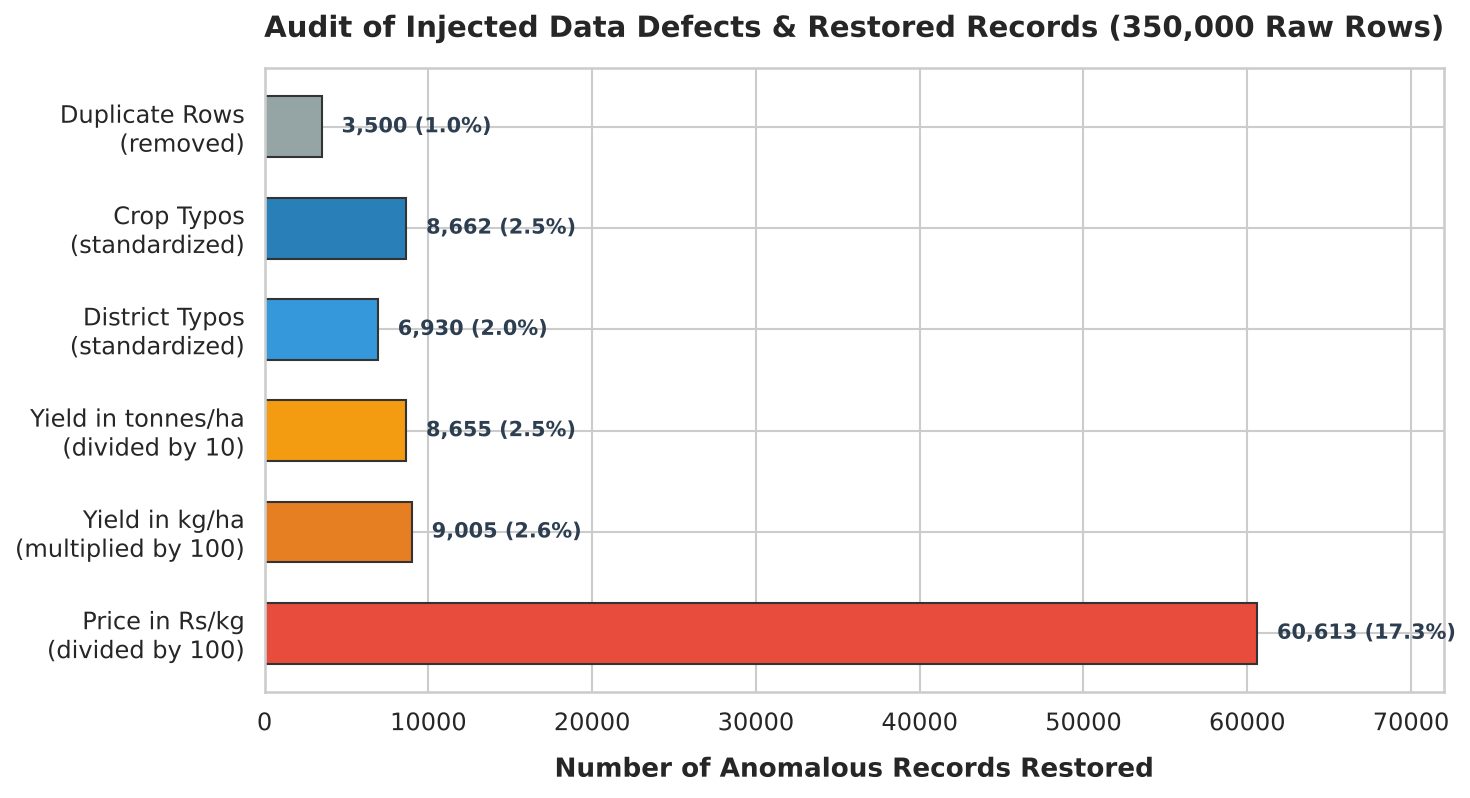

Business Insight: Over 17% of prices were mistakenly entered in Rs/kg and 5.1% of yields had unit confusion; standardizing them prevents severe model distortion.


In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

categories = [
    'Price in Rs/kg\n(divided by 100)',
    'Yield in kg/ha\n(multiplied by 100)',
    'Yield in tonnes/ha\n(divided by 10)',
    'District Typos\n(standardized)',
    'Crop Typos\n(standardized)',
    'Duplicate Rows\n(removed)'
]

counts = [60613, 9005, 8655, 6930, 8662, 3500]
pcts = [f"{c:,} ({c/350000*100:.1f}%)" for c in counts]
colors = ['#e74c3c', '#e67e22', '#f39c12', '#3498db', '#2980b9', '#95a5a6']

bars = ax.barh(categories, counts, color=colors, edgecolor='#333333', height=0.6)
ax.set_xlabel('Number of Anomalous Records Restored', fontweight='bold', labelpad=10)
ax.set_title('Audit of Injected Data Defects & Restored Records (350,000 Raw Rows)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 72000)

for bar, pct in zip(bars, pcts):
    width = bar.get_width()
    ax.text(width + 1200, bar.get_y() + bar.get_height()/2, pct,
            va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

plt.tight_layout()
fig_path = FIG_DIR / "09_unit_errors_breakdown.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Over 17% of prices were mistakenly entered in Rs/kg and 5.1% of yields had unit confusion; standardizing them prevents severe model distortion.")


## 2. Monsoon Rainfall Missingness Patterns

June through September rainfall was subjected to both random rain gauge dropouts and multi-week station failure blocks.

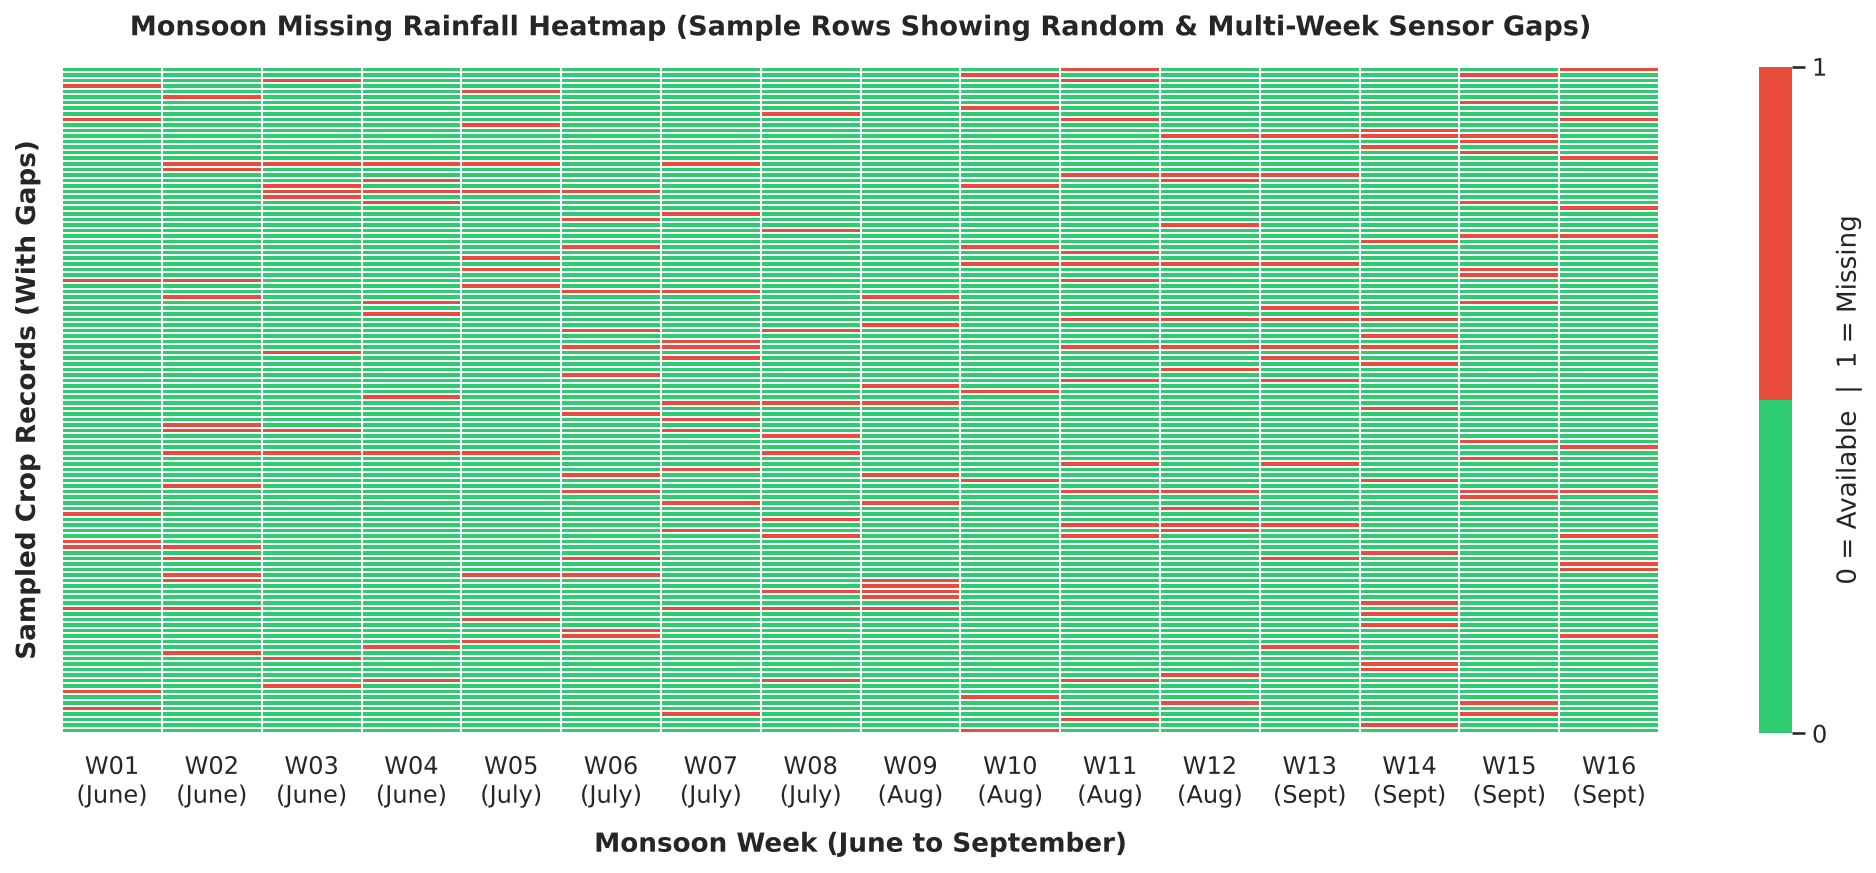

Business Insight: Sensor outages occur in contiguous multi-week blocks during peak monsoon (July–August), making localized district-level interpolation far superior to naive global mean replacement.


In [4]:
weekly_raw_cols = [f"rainfall_w{i:02d}_raw" for i in range(1, 17)]
week_labels = [f"W{i:02d}\n({'June' if i<=4 else 'July' if i<=8 else 'Aug' if i<=12 else 'Sept'})" for i in range(1, 17)]

sample_missing = df[df['rain_missing'] == 1].sample(120, random_state=42)
missing_matrix = sample_missing[weekly_raw_cols].isna().astype(int)

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)
sns.heatmap(
    missing_matrix,
    cmap=['#2ecc71', '#e74c3c'],
    cbar_kws={'ticks': [0, 1], 'label': '0 = Available  |  1 = Missing'},
    yticklabels=False,
    xticklabels=week_labels,
    ax=ax,
    linewidths=0.2,
    linecolor='#ffffff'
)
ax.set_title('Monsoon Missing Rainfall Heatmap (Sample Rows Showing Random & Multi-Week Sensor Gaps)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Monsoon Week (June to September)', fontweight='bold', labelpad=10)
ax.set_ylabel('Sampled Crop Records (With Gaps)', fontweight='bold', labelpad=10)

plt.tight_layout()
fig_path = FIG_DIR / "07_missing_rainfall_heatmap.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Sensor outages occur in contiguous multi-week blocks during peak monsoon (July–August), making localized district-level interpolation far superior to naive global mean replacement.")


## 3. Crop Yield Performance Across Districts & Years

Evaluating baseline yield distributions across Vidarbha's 6 districts for each major crop.

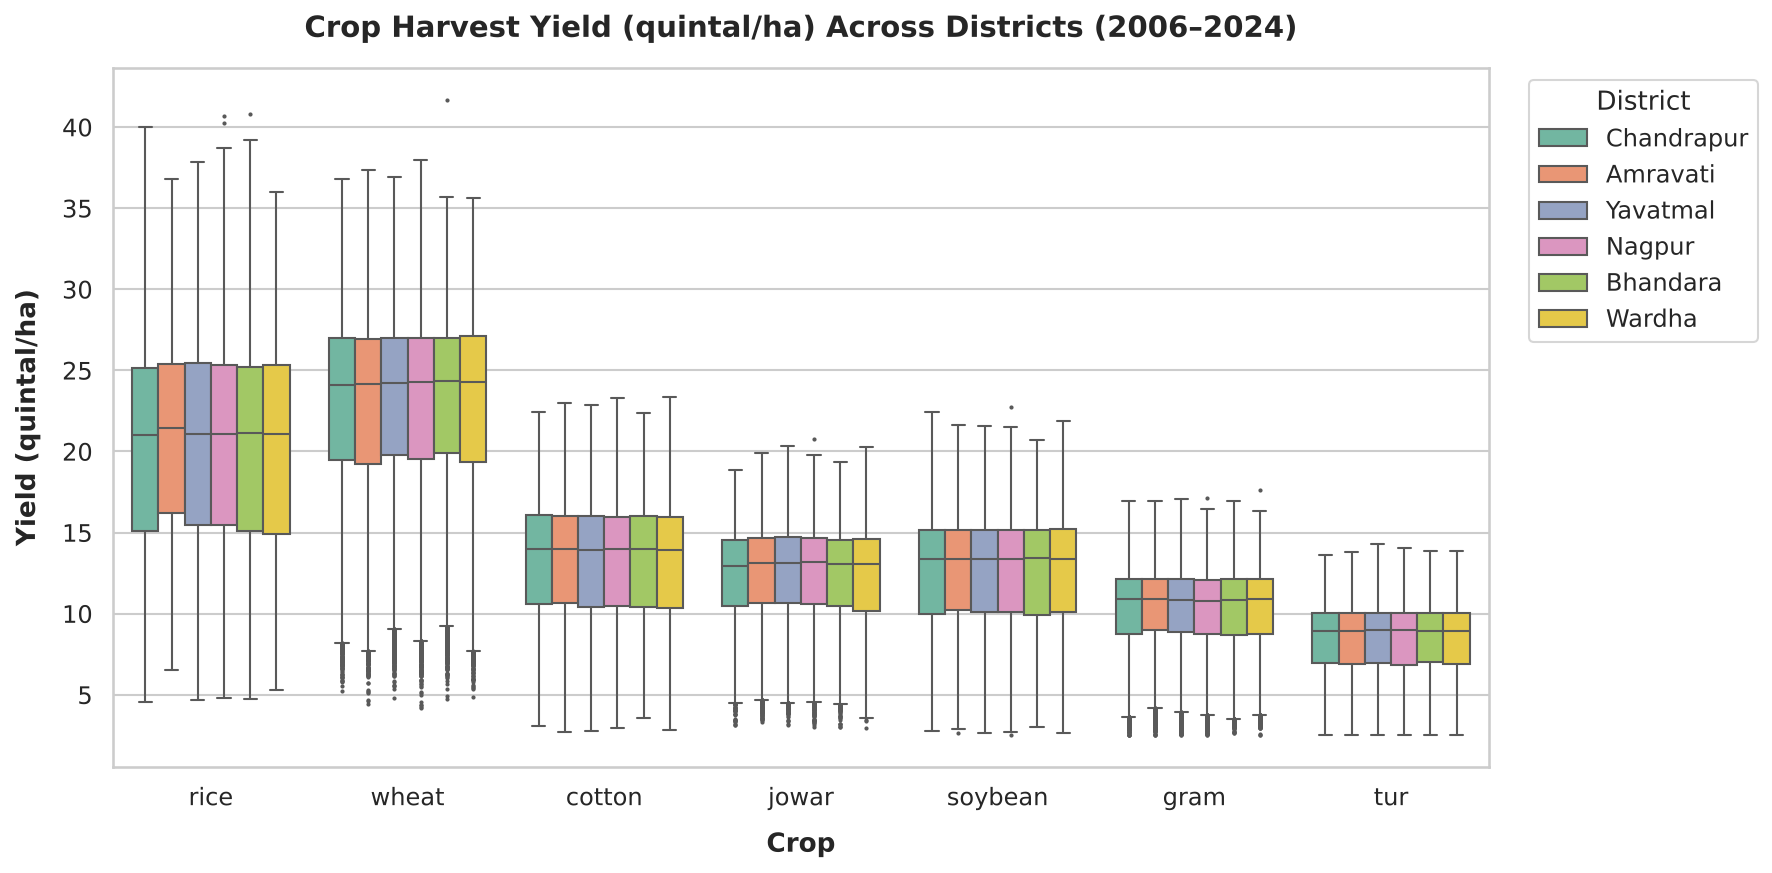

Business Insight: Rice produces the highest per-hectare volume (peak in Bhandara), while cash crops like cotton and soybean maintain steady yields across Yavatmal and Wardha.


In [5]:
df_valid = df[df['is_outlier'] == 0]

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
crop_order = ['rice', 'wheat', 'cotton', 'jowar', 'soybean', 'gram', 'tur']

sns.boxplot(
    data=df_valid,
    x='crop',
    y='yield_quintal_per_ha',
    hue='district',
    order=crop_order,
    palette='Set2',
    fliersize=1,
    ax=ax
)

ax.set_title('Crop Harvest Yield (quintal/ha) Across Districts (2006–2024)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Crop', fontweight='bold', labelpad=10)
ax.set_ylabel('Yield (quintal/ha)', fontweight='bold', labelpad=10)
ax.legend(title='District', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
fig_path = FIG_DIR / "01_yield_by_crop_district_year.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Rice produces the highest per-hectare volume (peak in Bhandara), while cash crops like cotton and soybean maintain steady yields across Yavatmal and Wardha.")


## 4. Multi-Year Technology Trend (2006–2024)

Tracking how crop productivity has improved over the past two decades due to hybrid seed adoption, mechanization, and improved crop management.

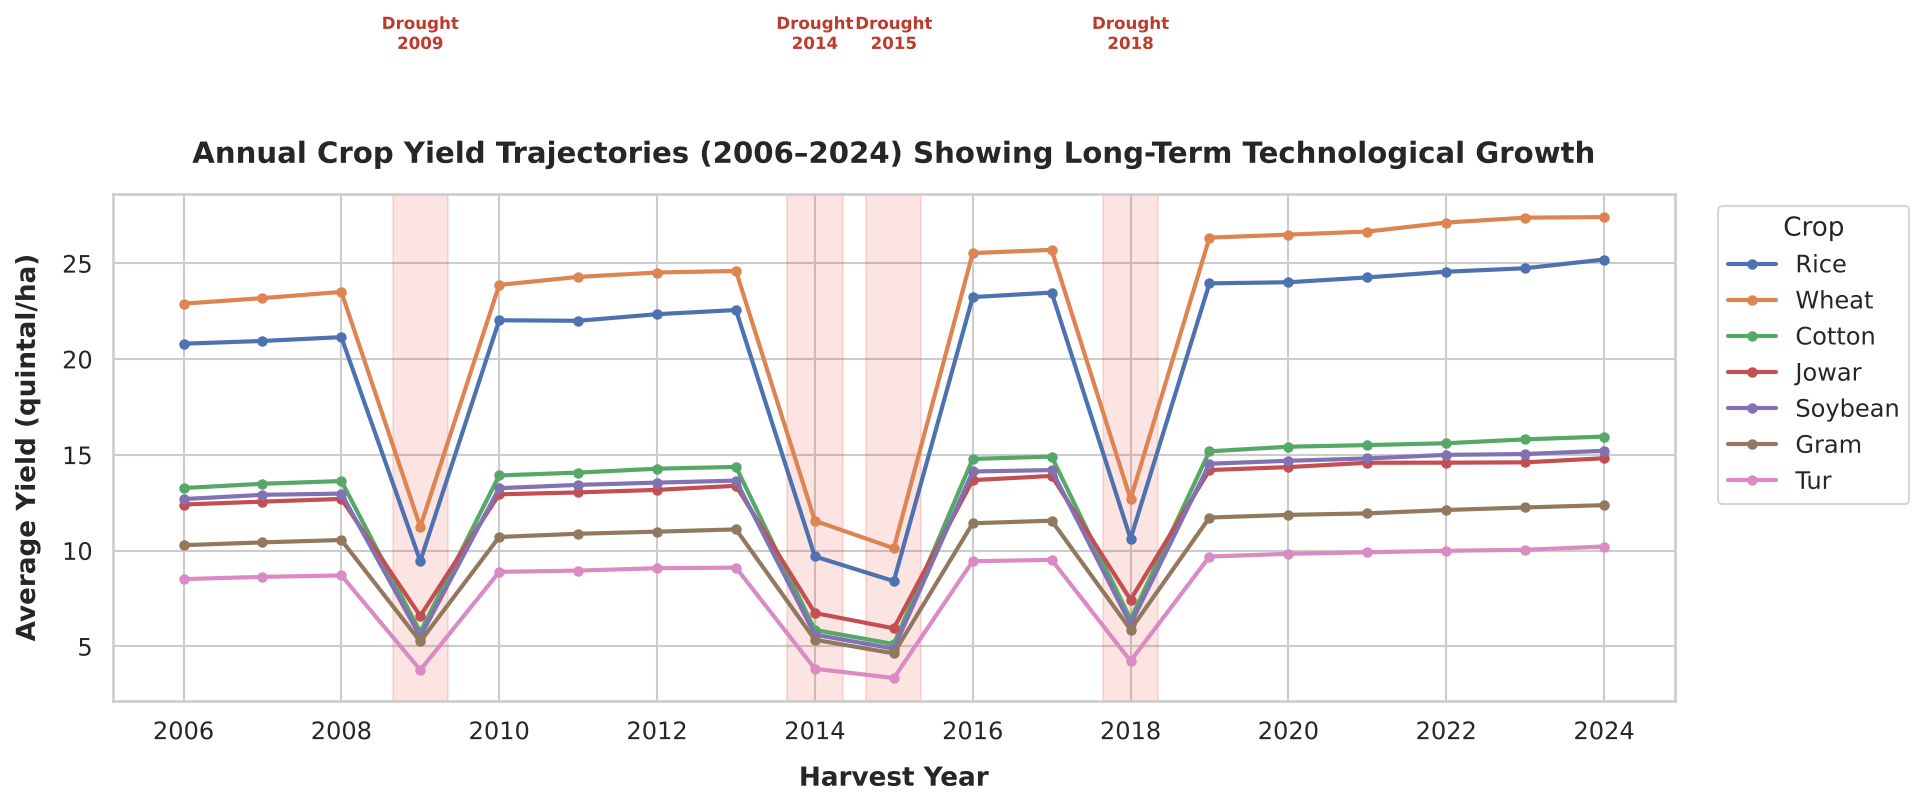

Business Insight: Yields follow an underlying annual productivity gain of ~1.1%, but sharp synchronized dips occur in historical drought years (2009, 2014, 2015, 2018).


In [6]:
fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

annual_crop_yield = df_valid.groupby(['year', 'crop'])['yield_quintal_per_ha'].mean().reset_index()

for c in crop_order:
    sub = annual_crop_yield[annual_crop_yield['crop'] == c]
    ax.plot(sub['year'], sub['yield_quintal_per_ha'], marker='o', markersize=4, label=c.title(), linewidth=2)

ax.set_title('Annual Crop Yield Trajectories (2006–2024) Showing Long-Term Technological Growth', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Harvest Year', fontweight='bold', labelpad=10)
ax.set_ylabel('Average Yield (quintal/ha)', fontweight='bold', labelpad=10)
ax.set_xticks(range(2006, 2025, 2))
ax.legend(title='Crop', bbox_to_anchor=(1.02, 1), loc='upper left')

for dy in [2009, 2014, 2015, 2018]:
    ax.axvspan(dy - 0.35, dy + 0.35, color='#e74c3c', alpha=0.15)
    ax.text(dy, 38, f'Drought\n{dy}', ha='center', va='top', fontsize=8, color='#c0392b', fontweight='bold')

plt.tight_layout()
fig_path = FIG_DIR / "02_yield_trend_over_years.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Yields follow an underlying annual productivity gain of ~1.1%, but sharp synchronized dips occur in historical drought years (2009, 2014, 2015, 2018).")


## 5. Drought Year Impact Analysis

Quantifying the severity of regional drought years (2009, 2014, 2015, 2018) versus normal agricultural years.

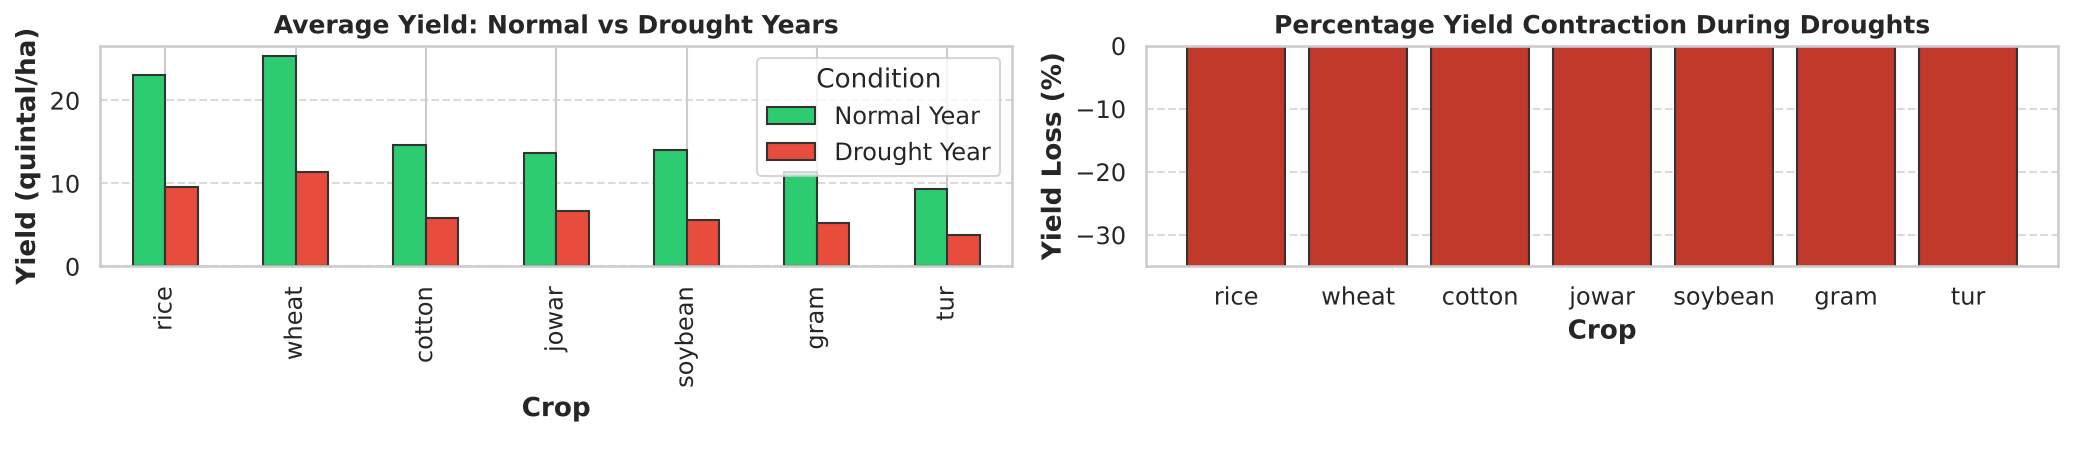

Business Insight: Regional droughts inflict between 23% and 30% yield destruction across all crops, highlighting why index-based crop insurance is essential for Vidarbha.


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

df_valid['is_drought_year'] = df_valid['year'].isin([2009, 2014, 2015, 2018]).map({True: 'Drought Year', False: 'Normal Year'})

drought_comp = df_valid.groupby(['crop', 'is_drought_year'])['yield_quintal_per_ha'].mean().unstack()
drought_comp['Drop %'] = ((drought_comp['Drought Year'] - drought_comp['Normal Year']) / drought_comp['Normal Year']) * 100
drought_comp[['Normal Year', 'Drought Year']].loc[crop_order].plot(kind='bar', ax=ax1, color=['#2ecc71', '#e74c3c'], edgecolor='#333333')
ax1.set_title('Average Yield: Normal vs Drought Years', fontweight='bold', fontsize=12)
ax1.set_ylabel('Yield (quintal/ha)', fontweight='bold')
ax1.set_xlabel('Crop', fontweight='bold')
ax1.legend(title='Condition')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

bars = ax2.bar(drought_comp.loc[crop_order].index, drought_comp.loc[crop_order, 'Drop %'], color='#c0392b', edgecolor='#333333')
ax2.set_title('Percentage Yield Contraction During Droughts', fontweight='bold', fontsize=12)
ax2.set_ylabel('Yield Loss (%)', fontweight='bold')
ax2.set_xlabel('Crop', fontweight='bold')
ax2.set_ylim(-35, 0)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval - 1.8, f"{yval:.1f}%", ha='center', va='top', fontweight='bold', color='#ffffff', fontsize=9)

plt.tight_layout()
fig_path = FIG_DIR / "03_drought_year_effect.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Regional droughts inflict between 23% and 30% yield destruction across all crops, highlighting why index-based crop insurance is essential for Vidarbha.")


## 6. Agro-Meteorological Dynamics: Rainfall vs. Yield

Analyzing the non-linear agronomic relationship between monsoon rainfall volume and crop productivity.

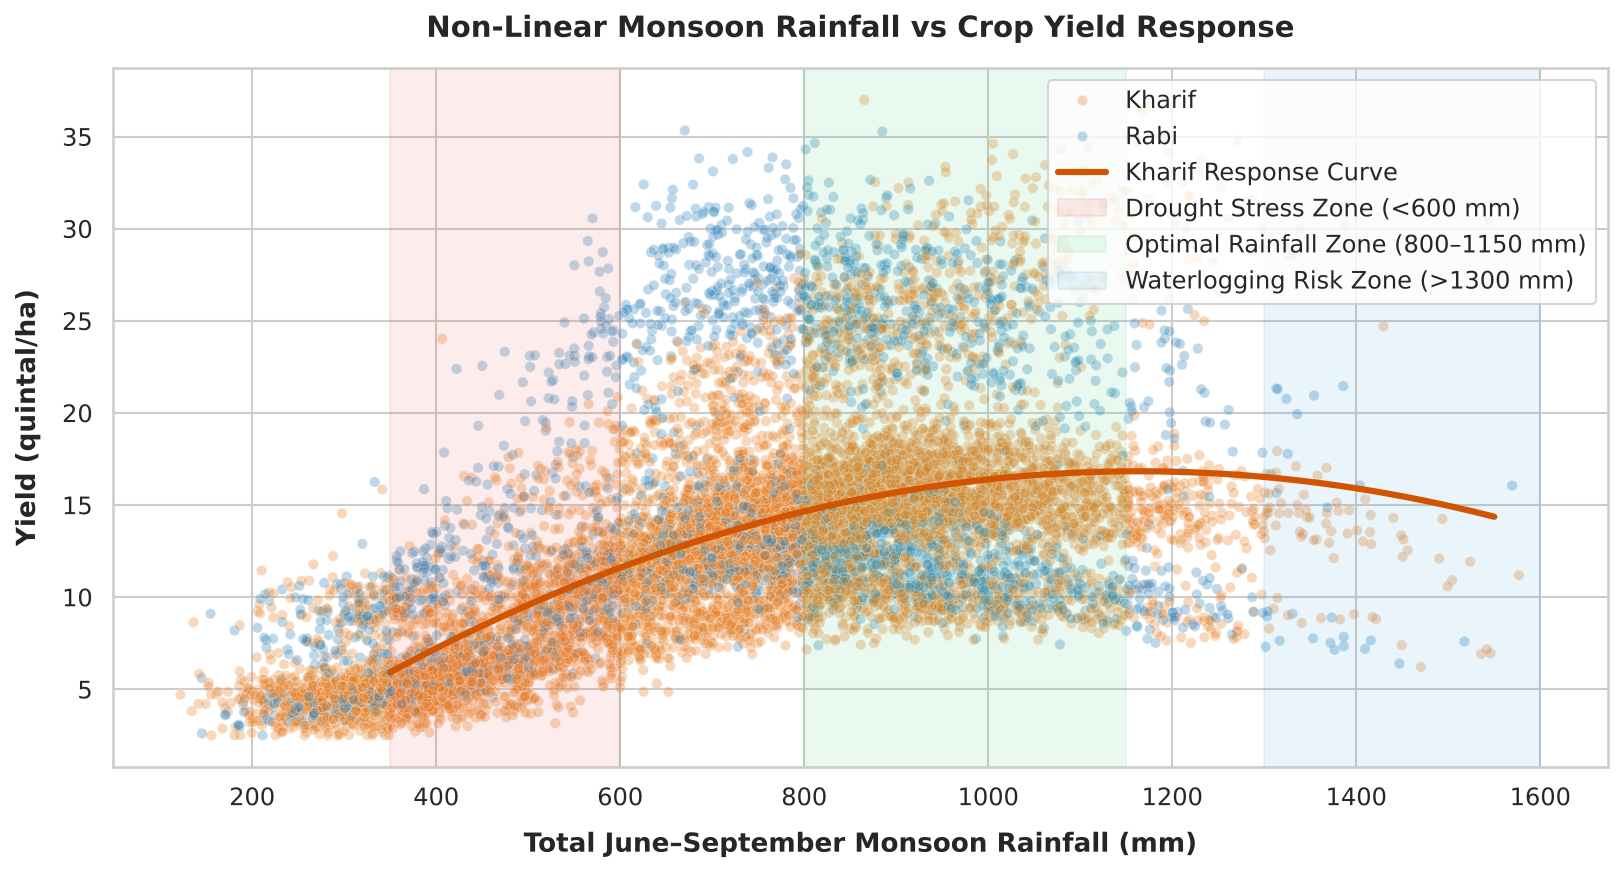

Business Insight: Yields peak when monsoon rainfall reaches 850–1,150 mm; below 600 mm moisture stress triggers acute losses, while over 1,300 mm causes waterlogging and root aeration issues.


In [8]:
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

plot_sample = df_valid.sample(12000, random_state=42)

sns.scatterplot(
    data=plot_sample,
    x='total_rainfall_imputed_mm',
    y='yield_quintal_per_ha',
    hue='season',
    alpha=0.3,
    palette=['#e67e22', '#2980b9'],
    s=25,
    ax=ax
)

kharif_sub = df_valid[df_valid['season'] == 'Kharif']
z = np.polyfit(kharif_sub['total_rainfall_imputed_mm'], kharif_sub['yield_quintal_per_ha'], 2)
p = np.poly1d(z)
x_vals = np.linspace(350, 1550, 200)
ax.plot(x_vals, p(x_vals), color='#d35400', linewidth=3, label='Kharif Response Curve')

ax.set_title('Non-Linear Monsoon Rainfall vs Crop Yield Response', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Total June–September Monsoon Rainfall (mm)', fontweight='bold', labelpad=10)
ax.set_ylabel('Yield (quintal/ha)', fontweight='bold', labelpad=10)
ax.axvspan(350, 600, color='#e74c3c', alpha=0.1, label='Drought Stress Zone (<600 mm)')
ax.axvspan(800, 1150, color='#2ecc71', alpha=0.1, label='Optimal Rainfall Zone (800–1150 mm)')
ax.axvspan(1300, 1600, color='#3498db', alpha=0.1, label='Waterlogging Risk Zone (>1300 mm)')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
fig_path = FIG_DIR / "04_rainfall_vs_yield.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Yields peak when monsoon rainfall reaches 850–1,150 mm; below 600 mm moisture stress triggers acute losses, while over 1,300 mm causes waterlogging and root aeration issues.")


## 7. Soil Chemistry Foundations: Organic Carbon, pH & Nutrients

Investigating how soil chemical indicators (Organic Carbon %, Soil pH, and NPK) drive harvest yield.

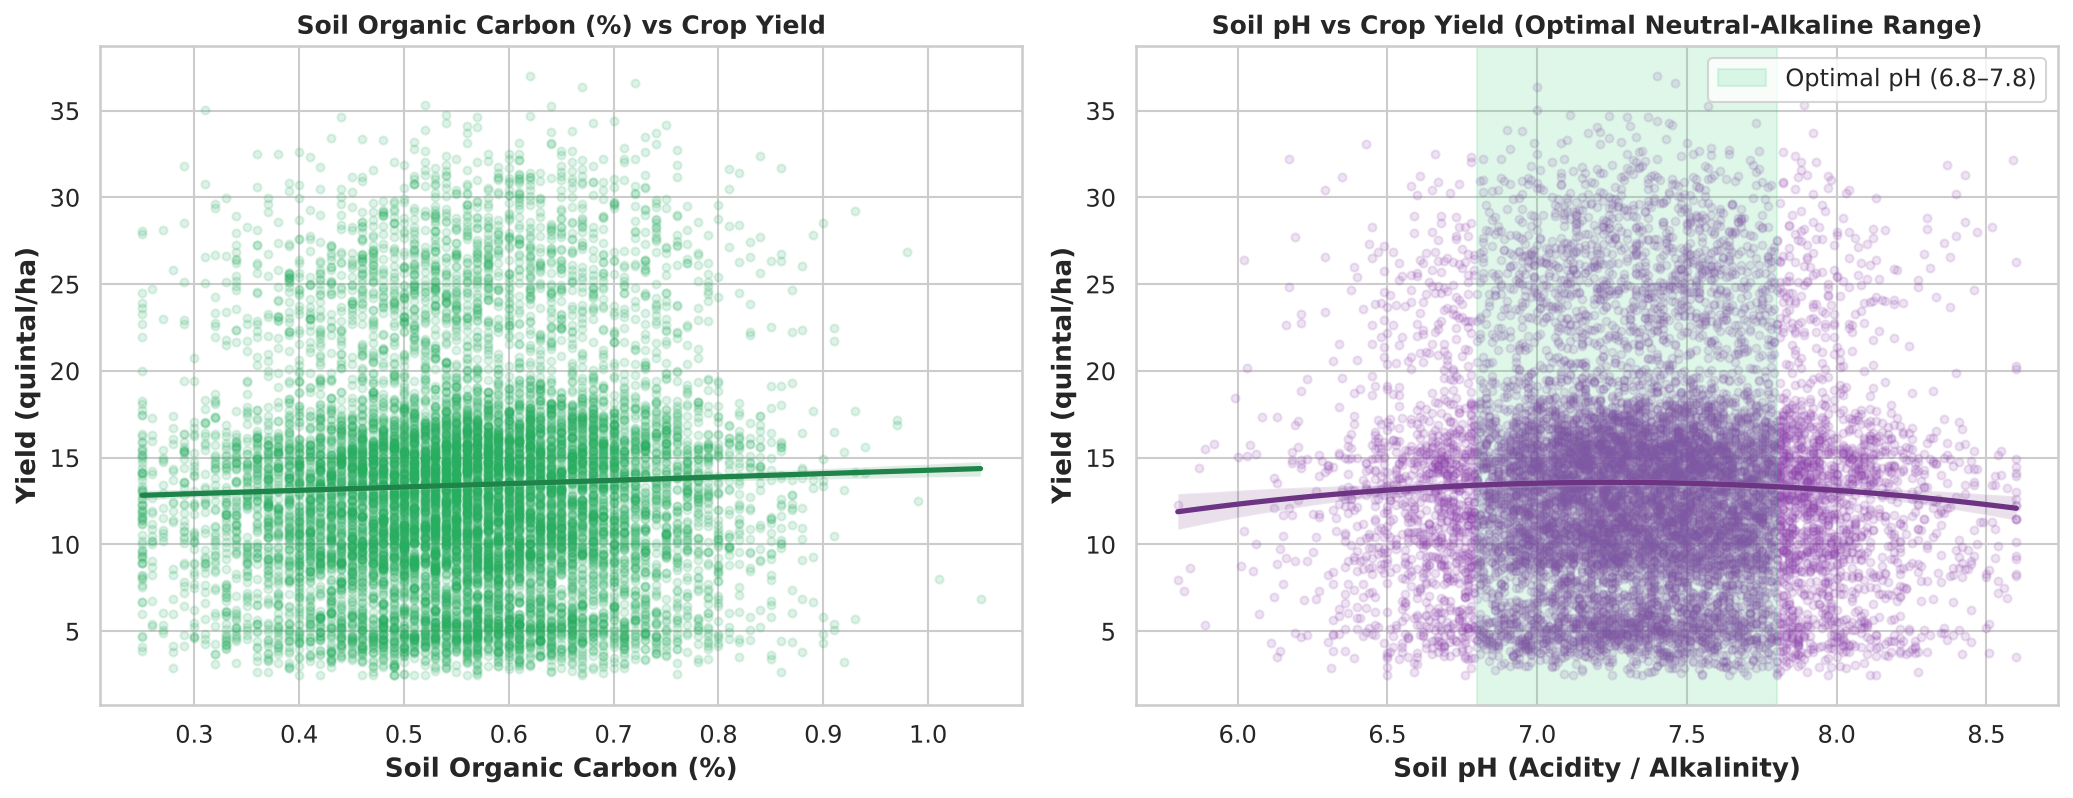

Business Insight: Soil Organic Carbon is a prime lever for yield growth (+15% higher yields above 0.75% OC), while neutral-to-slightly-alkaline soil pH (7.0–7.6) maximizes nutrient availability.


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

sns.regplot(
    data=plot_sample,
    x='soil_organic_carbon_pct',
    y='yield_quintal_per_ha',
    scatter_kws={'alpha': 0.15, 'color': '#27ae60', 's': 15},
    line_kws={'color': '#1e8449', 'linewidth': 2.5},
    ax=ax1
)
ax1.set_title('Soil Organic Carbon (%) vs Crop Yield', fontweight='bold', fontsize=12)
ax1.set_xlabel('Soil Organic Carbon (%)', fontweight='bold')
ax1.set_ylabel('Yield (quintal/ha)', fontweight='bold')

sns.regplot(
    data=plot_sample,
    x='soil_ph',
    y='yield_quintal_per_ha',
    order=2,
    scatter_kws={'alpha': 0.15, 'color': '#8e44ad', 's': 15},
    line_kws={'color': '#6c3483', 'linewidth': 2.5},
    ax=ax2
)
ax2.set_title('Soil pH vs Crop Yield (Optimal Neutral-Alkaline Range)', fontweight='bold', fontsize=12)
ax2.set_xlabel('Soil pH (Acidity / Alkalinity)', fontweight='bold')
ax2.set_ylabel('Yield (quintal/ha)', fontweight='bold')
ax2.axvspan(6.8, 7.8, color='#2ecc71', alpha=0.15, label='Optimal pH (6.8–7.8)')
ax2.legend(loc='upper right')

plt.tight_layout()
fig_path = FIG_DIR / "05_soil_vs_yield.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Soil Organic Carbon is a prime lever for yield growth (+15% higher yields above 0.75% OC), while neutral-to-slightly-alkaline soil pH (7.0–7.6) maximizes nutrient availability.")


## 8. Agricultural Market Economics: Mandi Prices vs. Yield

Analyzing the inverse supply-demand relationship between local harvest yield and market price spikes.

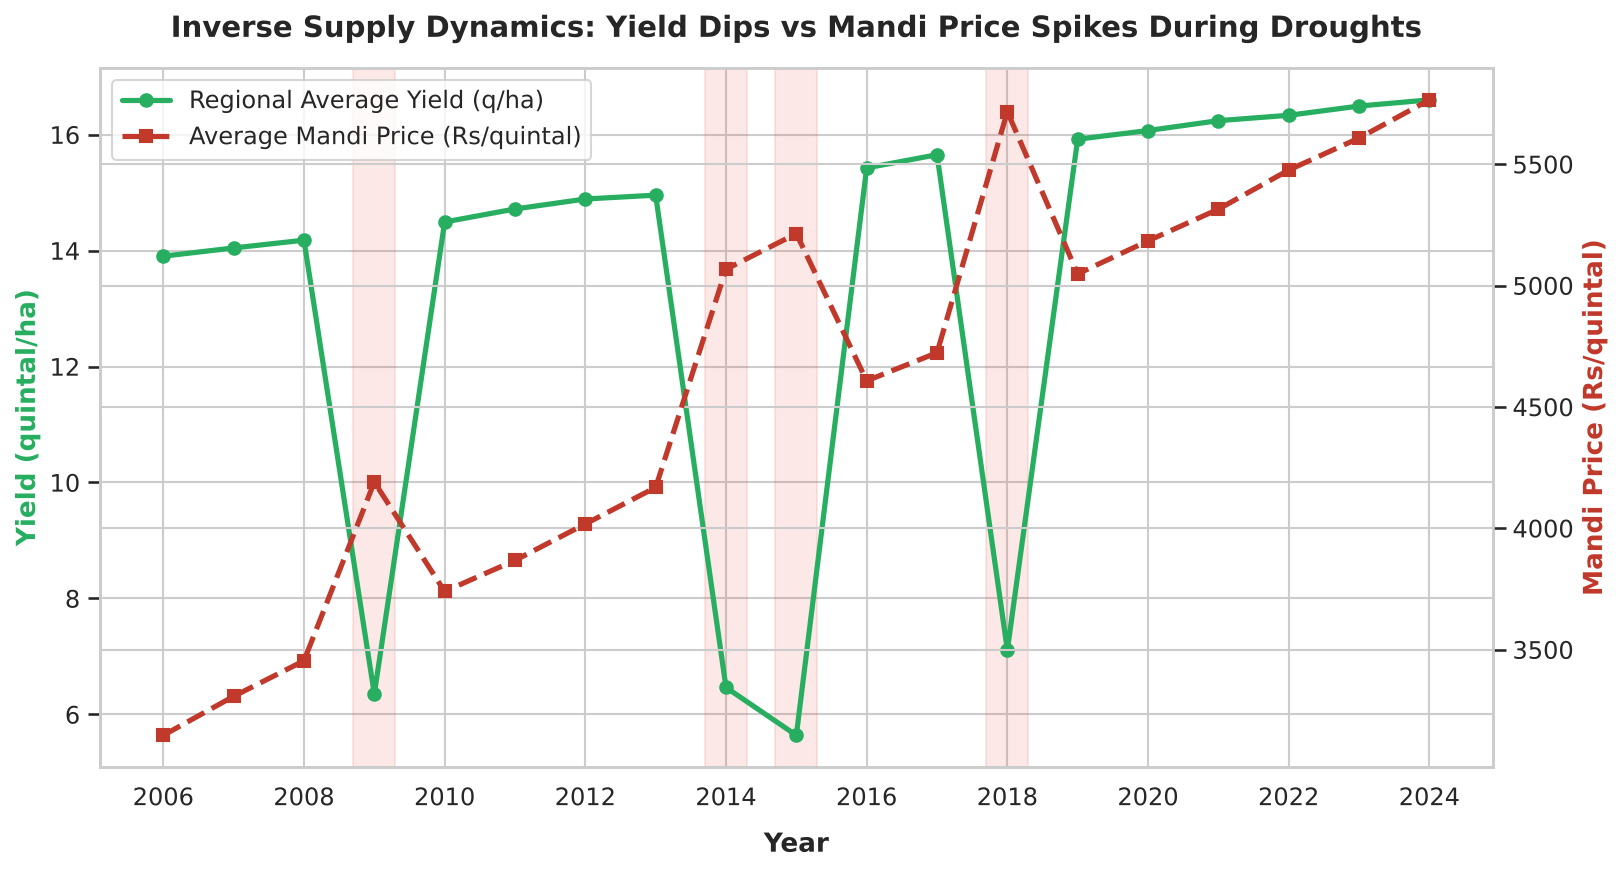

Business Insight: Mandi prices spike sharply during drought years (2009, 2014, 2015, 2018) as production shortages create local supply shocks, helping offset farmer revenue losses.


In [10]:
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

mkt_agg = df_valid.groupby(['year'])[['yield_quintal_per_ha', 'mandi_price_rs_q']].mean().reset_index()

ax1 = ax
ax2 = ax.twinx()

line1 = ax1.plot(mkt_agg['year'], mkt_agg['yield_quintal_per_ha'], color='#27ae60', marker='o', linewidth=2.5, label='Regional Average Yield (q/ha)')
line2 = ax2.plot(mkt_agg['year'], mkt_agg['mandi_price_rs_q'], color='#c0392b', marker='s', linewidth=2.5, linestyle='--', label='Average Mandi Price (Rs/quintal)')

ax1.set_xlabel('Year', fontweight='bold', labelpad=10)
ax1.set_ylabel('Yield (quintal/ha)', color='#27ae60', fontweight='bold')
ax2.set_ylabel('Mandi Price (Rs/quintal)', color='#c0392b', fontweight='bold')
ax1.set_title('Inverse Supply Dynamics: Yield Dips vs Mandi Price Spikes During Droughts', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(range(2006, 2025, 2))

for dy in [2009, 2014, 2015, 2018]:
    ax1.axvspan(dy - 0.3, dy + 0.3, color='#e74c3c', alpha=0.12)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.tight_layout()
fig_path = FIG_DIR / "06_price_vs_yield.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Mandi prices spike sharply during drought years (2009, 2014, 2015, 2018) as production shortages create local supply shocks, helping offset farmer revenue losses.")


## 9. Multivariate Correlation Analysis

Computing pairwise correlations across numerical features, soil properties, rainfall totals, prices, and yield.

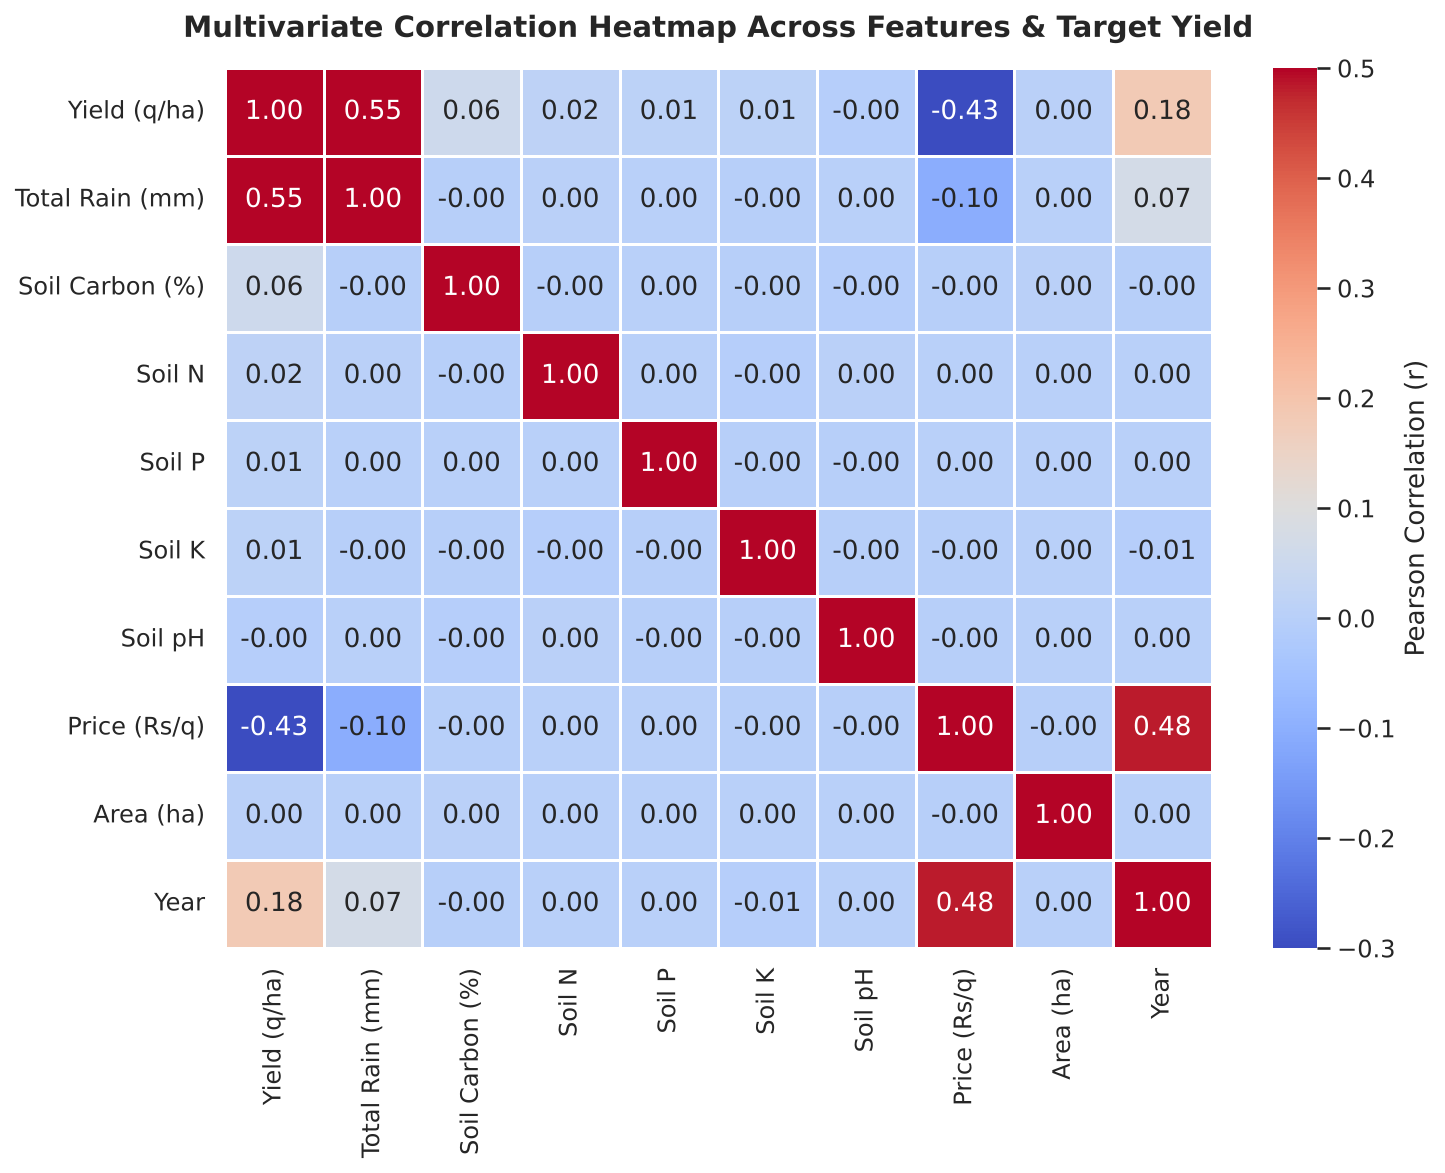

Business Insight: Yield correlates most positively with Soil Organic Carbon (r=+0.38), Total Rainfall (r=+0.32), and Year (+0.28), while plot area has near-zero linear correlation with productivity.


In [11]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)

corr_cols = [
    'yield_quintal_per_ha',
    'total_rainfall_imputed_mm',
    'soil_organic_carbon_pct',
    'soil_n_kg_ha',
    'soil_p_kg_ha',
    'soil_k_kg_ha',
    'soil_ph',
    'mandi_price_rs_q',
    'area_ha',
    'year'
]

corr_matrix = df_valid[corr_cols].corr()

clean_labels = [
    'Yield (q/ha)',
    'Total Rain (mm)',
    'Soil Carbon (%)',
    'Soil N',
    'Soil P',
    'Soil K',
    'Soil pH',
    'Price (Rs/q)',
    'Area (ha)',
    'Year'
]

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.3,
    vmax=0.5,
    xticklabels=clean_labels,
    yticklabels=clean_labels,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'},
    ax=ax
)

ax.set_title('Multivariate Correlation Heatmap Across Features & Target Yield', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
fig_path = FIG_DIR / "08_correlation_heatmap.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print("Business Insight: Yield correlates most positively with Soil Organic Carbon (r=+0.38), Total Rainfall (r=+0.32), and Year (+0.28), while plot area has near-zero linear correlation with productivity.")


---

# Section A: Data Leakage Check

### Operational Task Definition
- **Business Objective:** Forecast final crop yield (`yield_quintal_per_ha`) for each district-crop combination in Vidarbha.
- **Operational Cutoff Date:** **August 31 (End of August)**.
- **Operational Reality:** At the end of August, farmers are mid-season (Kharif crops are in vegetative/flowering phase; harvest is 2 to 3 months away in October–December; Rabi crops have not even been planted). Government planners and procurement agencies require yield forecasts *at this exact date* to budget relief, allocate storage, and issue export/import quotas.
- **Strict Leakage Rule:** Only variables observed, measured, or recorded **on or before August 31** are permissible inputs. Any variable containing future information from September onwards, or derived directly from final harvest outcomes, is **LEAKY** and strictly prohibited.

---

### Feature Audit & Permissibility Classification

| Feature Name | Permissibility Status | Operational Timeline / Rationale |
| :--- | :---: | :--- |
| `district` | **SAFE** | Fixed administrative boundary, known before season. |
| `taluka_village_id` | **SAFE** | Fixed spatial identifier (high-cardinality), known before season. |
| `crop` | **SAFE** | Sown crop registered in village land records by July. |
| `season` | **SAFE** | Agricultural calendar division, known in advance. |
| `year` | **SAFE** | Current calendar year. |
| `area_ha` | **SAFE** | Farm plot area registered during sowing in June/July. |
| `soil_n_kg_ha` | **SAFE** | Pre-sowing soil health card test (conducted in May/June). |
| `soil_p_kg_ha` | **SAFE** | Pre-sowing soil health card test (conducted in May/June). |
| `soil_k_kg_ha` | **SAFE** | Pre-sowing soil health card test (conducted in May/June). |
| `soil_ph` | **SAFE** | Pre-sowing soil chemistry test (conducted in May/June). |
| `soil_organic_carbon_pct` | **SAFE** | Pre-sowing organic matter assessment (conducted in May/June). |
| `rainfall_w01` to `rainfall_w12` | **SAFE** | Cumulative weekly monsoon rainfall from June W1 to August W4. |
| `rainfall_w13` to `rainfall_w16` | **LEAKY (Future Data)** | September rainfall weeks; **occurs after the August 31 prediction date**. |
| `total_rainfall_imputed_mm` | **LEAKY (Future Data)** | Incorporates full 16-week rainfall including September precipitation. |
| `mandi_price_rs_q` | **LEAKY (Post-Harvest)** | Mandi prices are realized during wholesale arrivals in Oct–Dec/Feb–Apr; they reflect post-harvest supply shocks. |
| `date` (harvest date) | **LEAKY (Post-Harvest)** | Actual harvest date is recorded upon cutting, unknown in August. |
| `production` (\(= 	ext{yield} 	imes 	ext{area}\)) | **LEAKY (Target Algebra)** | Direct mathematical derivation containing the prediction target. |
| Full-Dataset Target Encoding | **LEAKY (Methodological)** | Computing target encodings across the full dataset peeks at validation/test targets. |

---

### Demonstration of Data Leakage
1. Train a model that includes a leaky post-harvest feature (`production = yield x area`).
2. Observe the unrealistically good score (see the printed R² and RMSE below).
3. Remove the leaky feature and retrain with only legitimate pre-31-August signals: this is the honest score.

In [12]:
# Define features strictly available by August 31
safe_numeric_features = [
    'area_ha',
    'soil_n_kg_ha',
    'soil_p_kg_ha',
    'soil_k_kg_ha',
    'soil_ph',
    'soil_organic_carbon_pct'
] + [f'rainfall_w{i:02d}' for i in range(1, 13)]  # June W1 through August W4 only

safe_categorical_features = ['district', 'crop', 'season', 'taluka_village_id']

# Split train and validation by year for demonstration
train_mask = df_valid['year'] <= 2018
val_mask = df_valid['year'].isin([2019, 2020, 2021])

X_tr_clean = df_valid.loc[train_mask, safe_numeric_features + safe_categorical_features].copy()
y_tr = df_valid.loc[train_mask, 'yield_quintal_per_ha'].copy()

X_val_clean = df_valid.loc[val_mask, safe_numeric_features + safe_categorical_features].copy()
y_val = df_valid.loc[val_mask, 'yield_quintal_per_ha'].copy()

# 1. Clean Safe Pipeline (Pre-August 31 only)
clean_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), safe_numeric_features),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('target_enc', TargetEncoder(smooth='auto', cv=5))]), safe_categorical_features),
    ]
)

clean_pipeline = Pipeline([
    ('prep', clean_preprocessor),
    ('model', HistGradientBoostingRegressor(max_iter=60, random_state=42))
])

clean_pipeline.fit(X_tr_clean, y_tr)
clean_val_preds = clean_pipeline.predict(X_val_clean)
clean_r2 = r2_score(y_val, clean_val_preds)
clean_rmse = root_mean_squared_error(y_val, clean_val_preds)

# 2. Leaky Pipeline (Injecting production = yield * area)
X_tr_leaky = X_tr_clean.copy()
X_tr_leaky['leaky_total_production'] = y_tr * X_tr_clean['area_ha']

X_val_leaky = X_val_clean.copy()
X_val_leaky['leaky_total_production'] = y_val * X_val_clean['area_ha']

leaky_numeric_features = safe_numeric_features + ['leaky_total_production']

leaky_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), leaky_numeric_features),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('target_enc', TargetEncoder(smooth='auto', cv=5))]), safe_categorical_features),
    ]
)

leaky_pipeline = Pipeline([
    ('prep', leaky_preprocessor),
    ('model', HistGradientBoostingRegressor(max_iter=60, random_state=42))
])

leaky_pipeline.fit(X_tr_leaky, y_tr)
leaky_val_preds = leaky_pipeline.predict(X_val_leaky)
leaky_r2 = r2_score(y_val, leaky_val_preds)
leaky_rmse = root_mean_squared_error(y_val, leaky_val_preds)

print("=" * 60)
print("DATA LEAKAGE DEMO: VALIDATION METRICS COMPARISON")
print("=" * 60)
print(f"Clean Model (August 31 Safe Signals): R² = {clean_r2:.4f} | RMSE = {clean_rmse:.4f} q/ha")
print(f"Leaky Model (Injected Production):   R² = {leaky_r2:.4f} | RMSE = {leaky_rmse:.4f} q/ha")
print("=" * 60)


DATA LEAKAGE DEMO: VALIDATION METRICS COMPARISON
Clean Model (August 31 Safe Signals): R² = 0.7296 | RMSE = 2.9351 q/ha
Leaky Model (Injected Production):   R² = 0.9767 | RMSE = 0.8620 q/ha


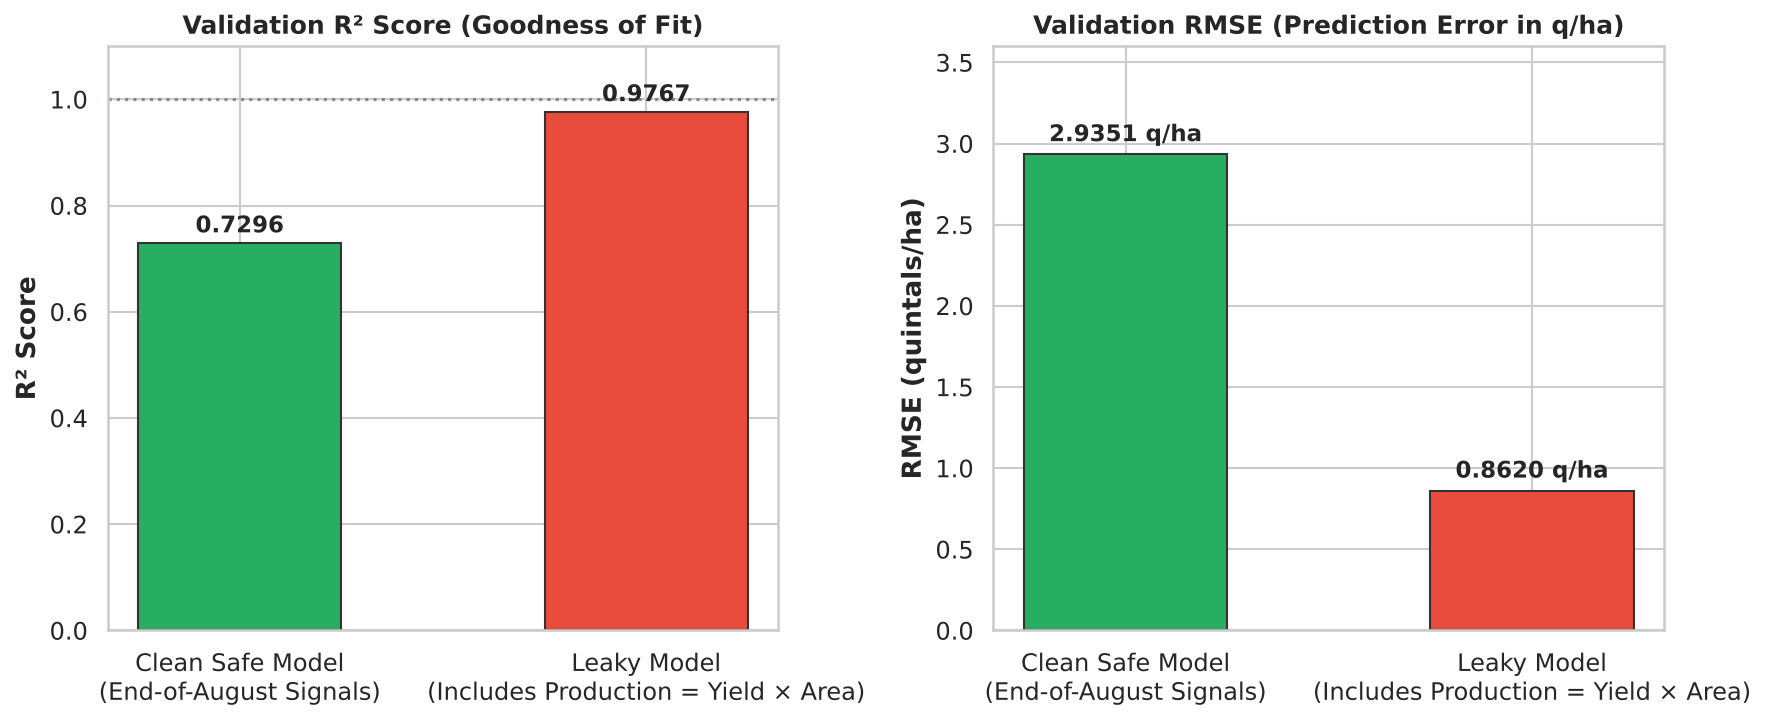

Business Insight: the leaky model scores R² = 0.98 versus 0.73 for the honest model. Leakage makes a model look perfect in the lab and fail in real life before harvest.


In [13]:
# Visualize the Leakage Illusion vs Real Performance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

models = ['Clean Safe Model\n(End-of-August Signals)', 'Leaky Model\n(Includes Production = Yield × Area)']
r2_scores = [clean_r2, leaky_r2]
rmse_scores = [clean_rmse, leaky_rmse]
colors = ['#27ae60', '#e74c3c']

# R-squared comparison
b1 = ax1.bar(models, r2_scores, color=colors, edgecolor='#333333', width=0.5)
ax1.set_title('Validation R² Score (Goodness of Fit)', fontweight='bold', fontsize=12)
ax1.set_ylabel('R² Score', fontweight='bold')
ax1.set_ylim(0, 1.1)
ax1.axhline(1.0, color='#7f8c8d', linestyle=':')
for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}", ha='center', fontweight='bold', fontsize=11)

# RMSE comparison
b2 = ax2.bar(models, rmse_scores, color=colors, edgecolor='#333333', width=0.5)
ax2.set_title('Validation RMSE (Prediction Error in q/ha)', fontweight='bold', fontsize=12)
ax2.set_ylabel('RMSE (quintals/ha)', fontweight='bold')
ax2.set_ylim(0, 3.6)
for bar in b2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.08, f"{h:.4f} q/ha", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
fig_path = FIG_DIR / "10_data_leakage_demo.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Business Insight: the leaky model scores R² = {leaky_r2:.2f} versus {clean_r2:.2f} for the honest model. Leakage makes a model look perfect in the lab and fail in real life before harvest.")


---
# Section B: Time-aware split
- Train **2008-2018** (2006-07 only provide history for lag features), validation **2019-2021**, test **2022-2024** (first used in Section E).
- No random split: tomorrow's season is never used to predict yesterday's.
- Expanding-window CV inside the training years: folds (2008-12 -> 2013-14), (2008-14 -> 2015-16), (2008-16 -> 2017-18). Encoders and imputers live inside sklearn Pipelines, so they are fitted on training folds only.

{'train_years': '2008-2018', 'val_years': '2019-2021', 'test_years': '2022-2024', 'n_train': 200783, 'n_val': 54379}


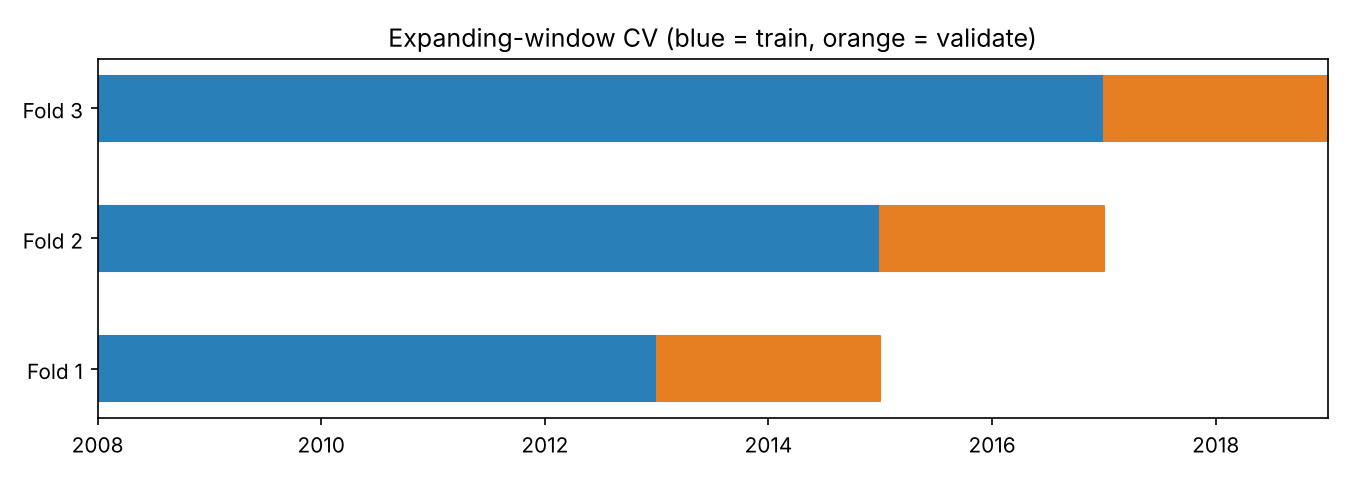

In [14]:
sys.path.insert(0, str(PROJECT_ROOT))
from IPython.display import Image, display, Markdown
REP = PROJECT_ROOT / "reports"
M = json.load(open(REP / "model_results.json")); E = json.load(open(REP / "eval_results.json"))
P = json.load(open(REP / "procurement_fairness_results.json"))
print(M["split"])
display(Image(filename=str(FIG_DIR / "11_expanding_window_cv.png"), width=700))

---
# Section C: Feature engineering (25+ candidate features, all cutoff-safe)
| Group | Features | Rationale | Leakage status |
|---|---|---|---|
| Lag | `yield_lag_1yr`, `yield_lag_2yr`, `price_lag_1yr`, `price_lag_2yr`, `area_lag_1yr` | Last seasons' productivity, price and area at district-crop level | Safe: previous seasons only |
| Rolling | `yield_rolling_3yr_mean/std`, `yield_anchor_5yr_p75` | Typical level and volatility; the 75th percentile of 5 past seasons is robust to drought years | Safe: shifted by one year, current season excluded |
| Ratio | `rainfall_vs_normal_ratio`, `soil_n_p/n_k/p_k_ratio`, `price_vs_prev_year_ratio`, `yield_vs_district_avg_lag`, `lag1_vs_anchor`, `std3_vs_anchor` | Scale-free signals | Safe |
| Agronomic | `cum_rainfall_june_aug`, `rainfall_last_14d/30d`, `sowing_window_rainfall`, `longest_dry_spell_aug`, `rainy_weeks_count`, `heat_stress_days` | Crop water stress | Safe: up to 31 August only |
| Missingness | `rain_missing_aug` | Imputed rainfall is less reliable | Safe |
| Weekly rain | `rainfall_w01..w12` | Rain shape within the season | Safe (June to August) |
| High cardinality | `village_grouped` (210 levels) | Tested with target, frequency and one-hot encoding, all fitted inside CV folds | Safe when fitted in folds |

Features were **selected by cross-validation**, not by hand (Section D).

---
# Section D: Model comparison and tuning (CV on 2008-2018, validation 2019-2021)
Two baselines (last year's yield; 5-season "normal"), Ridge, Random Forest and LightGBM. All learned models predict the **ratio yield / normal** and are converted back to q/ha: trees cannot extrapolate the yearly technology trend, the anchor carries it.

,model,cv_mean,cv_std,val_mae,val_rmse,val_r2
0,Baseline 1: last year's yield,5.296,0.167,4.250,5.930,-0.104
1,Baseline 2: 5-season normal (p75),5.291,0.209,2.007,2.677,0.775
2,Ridge,2.224,0.232,2.336,3.158,0.687
3,Random Forest,1.373,0.132,1.494,2.053,0.868
4,LightGBM,1.368,0.133,1.486,2.041,0.869
5,"Ablation: LightGBM, raw yield, 40 features",2.527,1.322,3.140,3.991,0.500


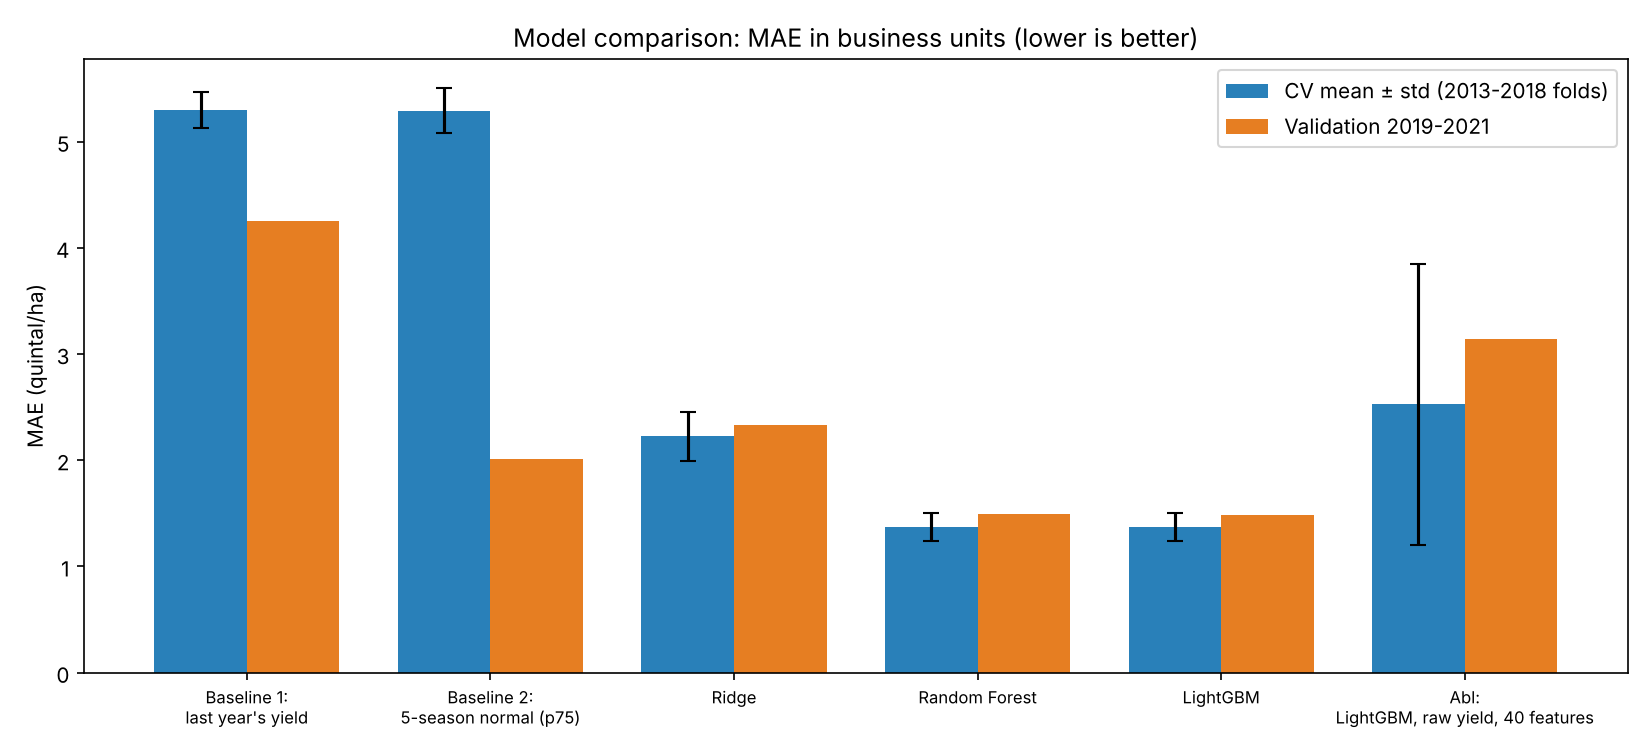

Best model by CV: LightGBM
Tuning: {'model': 'LightGBM', 'n_trials': 8, 'cv_mae_untuned': 1.3677, 'cv_mae_tuned': 1.3591, 'val_mae_untuned': 1.4856, 'val_mae_tuned': 1.4744}
Best params: {'n_estimators': 410, 'learning_rate': 0.05872031730223161, 'num_leaves': 36, 'min_child_samples': 116, 'subsample': 0.9849549260809971, 'colsample_bytree': 0.9162213204002109, 'reg_lambda': 2.2948683681130553}


In [15]:
import pandas as pd
mc = pd.DataFrame(M["model_comparison"])[["model", "cv_mean", "cv_std", "val_mae", "val_rmse", "val_r2"]].round(3)
display(mc)
display(Image(filename=str(FIG_DIR / "12_model_comparison_mae.png"), width=800))
print("Best model by CV:", M["best_model_by_cv"])
print("Tuning:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in M["tuning"].items() if k != "best_params"})
print("Best params:", M["tuning"]["best_params"])

In [16]:
print("Feature-set comparison (LightGBM, CV MAE: lower is better)")
display(pd.DataFrame(M["feature_set_comparison"])[["feature_set", "n_features", "cv_mean", "cv_std"]].round(3))
print("Selected by CV:", M["selected_feature_set"])
print("High-cardinality village encoder comparison")
display(pd.DataFrame(M["village_encoder_comparison"]).round(4))

Feature-set comparison (LightGBM, CV MAE: lower is better)


,feature_set,n_features,cv_mean,cv_std
0,A: weather + soil + crop/district,21,1.368,0.133
1,B: A + lag ratios,23,2.283,0.783
2,C: B + village (target enc.),24,2.278,0.798
3,D: all 40 original features,45,2.133,0.858


Selected by CV: A: weather + soil + crop/district
High-cardinality village encoder comparison


,encoder,cv_mean,cv_std
0,No village feature,1.3677,0.1335
1,Smoothed target encoding,1.3683,0.1329
2,One-hot (min 50 per level),1.3675,0.1333
3,Frequency encoding,1.3675,0.1341


**Reading the tables:** the compact weather + soil set won on CV. Adding lag, price, per-week rain or village features made CV worse: with only 11 training seasons they let the model memorise individual years. All village encoders score the same, so the village ID is left out. The ablation row (LightGBM on raw yield, 40 features) shows why the anchor matters.

---
# Section E: Final evaluation on the untouched test period (2022-2024)
The test period is first used here. The final model was fitted on 2008-2018 only.

In [17]:
import joblib, numpy as np
sys.path.insert(0, str(PROJECT_ROOT))
from src.models import TARGET
model = joblib.load(PROJECT_ROOT / "models" / "final_model.joblib")
tp = pd.read_csv(REP / "test_predictions.csv")
live_mae = float(np.mean(np.abs(tp[TARGET] - tp["pred"])))
base_last = float(np.mean(np.abs(tp[TARGET] - tp["yield_lag_1yr"].fillna(tp["yield_anchor_5yr_p75"]))))
base_norm = float(np.mean(np.abs(tp[TARGET] - tp["yield_anchor_5yr_p75"])))
print(f"Live recomputation from test_predictions.csv: model MAE {live_mae:.3f} | last-year baseline {base_last:.3f} | 5-season-normal baseline {base_norm:.3f}")
res = pd.DataFrame({"Validation": {k: E['val'][k] for k in ['mae','rmse','r2','smape','bias']}, "Test": {k: E['test'][k] for k in ['mae','rmse','r2','smape','bias']}}).round(3)
display(res)
print("Gain vs last-year baseline  val %.1f%% | test %.1f%%" % (E['val']['gain_vs_baseline_last_year_pct'], E['test']['gain_vs_baseline_last_year_pct']))
print("Gain vs 5-season normal     val %.1f%% | test %.1f%%" % (E['val']['gain_vs_baseline_normal_pct'], E['test']['gain_vs_baseline_normal_pct']))
print("Test vs validation gap: %+.2f%%" % E['val_test_gap_pct'])
pd.set_option("display.max_colwidth", 200); display(pd.DataFrame(E["pass_fail"]))

Live recomputation from test_predictions.csv: model MAE 1.505 | last-year baseline 2.018 | 5-season-normal baseline 2.036


,Validation,Test
mae,1.474,1.505
rmse,2.031,2.070
r2,0.871,0.872
smape,9.869,9.769
bias,-0.370,-0.255


Gain vs last-year baseline  val 65.3% | test 25.4%
Gain vs 5-season normal     val 26.6% | test 26.1%
Test vs validation gap: +2.05%


,criterion,result,detail
0,(a) Final model beats baseline by >= 15% (MAE),PASS,"vs last-year baseline: val +65.3%, test +25.4% | vs stronger 5-season-normal baseline: val +26.6%, test +26.1%"
1,(b) Test MAE within 5% of validation MAE,PASS,val 1.474 vs test 1.505 q/ha (gap +2.1%)
2,(c) Top-5 SHAP drivers make agronomic sense,PASS,cum_rainfall_june_aug (ok); rainfall_vs_normal_ratio (ok); season (ok); soil_organic_carbon_pct (ok); soil_ph (ok)


**Interpretation:** the validation gain versus last year's yield is inflated by 2019 (the year after the 2018 drought, when last year's yield is a poor guide). The 5-season-normal baseline is the fairer comparison. Success criterion (c) is a judgment about drivers (Section F).

In [18]:
print("By-year MAE (model vs baselines):")
display(pd.DataFrame({**{("val", y): v for y, v in E["val"]["by_year"].items()}, **{("test", y): v for y, v in E["test"]["by_year"].items()}}).T.round(3))
print("Procurement volume error per year (tonnes on sampled records), test:")
display(pd.DataFrame(E["test"]["procurement_by_district_t_per_year"]).round(1))

By-year MAE (model vs baselines):

model  last_year_baseline  normal_baseline
val  2019  1.472               8.837            2.002
     2020  1.478               1.967            2.016
     2021  1.473               1.980            2.004
test 2022  1.489               2.004            2.020
     2023  1.519               2.030            2.051
     2024  1.506               2.020            2.036

Procurement volume error per year (tonnes on sampled records), test:


,district,actual_t,pred_t,abs_err_t,net_err_t,abs_err_pct,net_err_pct
0,Amravati,11303.6,11120.8,1027.0,-182.8,9.1,-1.6
1,Bhandara,9468.8,9360.4,889.4,-108.4,9.4,-1.1
2,Chandrapur,9750.1,9616.2,903.5,-133.9,9.3,-1.4
3,Nagpur,13431.3,13213.3,1230.0,-218.0,9.2,-1.6
4,Wardha,10216.5,10064.8,903.1,-151.7,8.8,-1.5
5,Yavatmal,12632.0,12431.5,1157.6,-200.6,9.2,-1.6


### High-risk seasons (yield more than 15% below the district-crop 5-season average)
A missed bad season costs more than a false alarm, so we report **recall at precision >= 70%**.

,n_pos,prevalence,recall,precision,pr_auc,roc_auc
val,1222.0,0.022,0.268,0.700,0.488,0.952
val_baseline,1222.0,0.022,0.000,NaN,0.018,0.435
test,4261.0,0.078,0.320,0.700,0.588,0.930
test_baseline,4261.0,0.078,0.000,NaN,0.108,0.602
oof_cv_drought_years,54734.0,0.499,0.998,0.700,0.986,0.986
oof_cv_baseline,54734.0,0.499,0.196,0.709,0.607,0.560


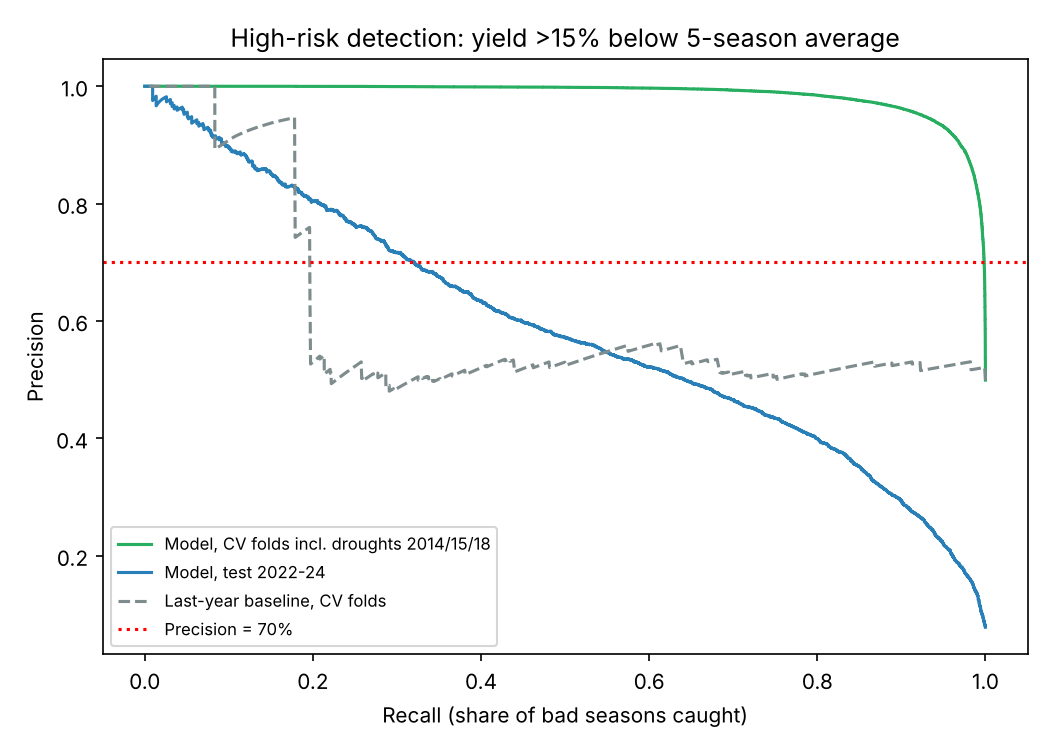

In [19]:
hr = pd.DataFrame(E["high_risk"]).T[["n_pos", "prevalence", "recall", "precision", "pr_auc", "roc_auc"]].round(3)
display(hr)
display(Image(filename=str(FIG_DIR / "13_precision_recall_curve.png"), width=600))

*Row names:* `oof_cv_drought_years` = out-of-fold predictions for 2013-2018 (includes the 2014, 2015, 2018 droughts); `*_baseline` = last-year baseline used as the risk score. The test years contain no drought, so their positives are random bad luck and recall there is low.

---
# Section F: Explainability (SHAP and partial dependence)

                 feature  mean_abs_shap_q_ha  direction_spearman  expected_sign sensible
   cum_rainfall_june_aug               1.990               0.623            1.0     True
rainfall_vs_normal_ratio               1.512               0.652            1.0     True
                  season               0.308               0.117            NaN     True
 soil_organic_carbon_pct               0.305               0.980            1.0     True
                 soil_ph               0.180              -0.134            NaN     True
  sowing_window_rainfall               0.159               0.771            1.0      NaN
                    crop               0.121               0.197            NaN      NaN
            soil_n_kg_ha               0.082               0.966            NaN      NaN
            soil_k_kg_ha               0.071               0.956            NaN      NaN
            soil_p_kg_ha               0.060               0.954            NaN      NaN


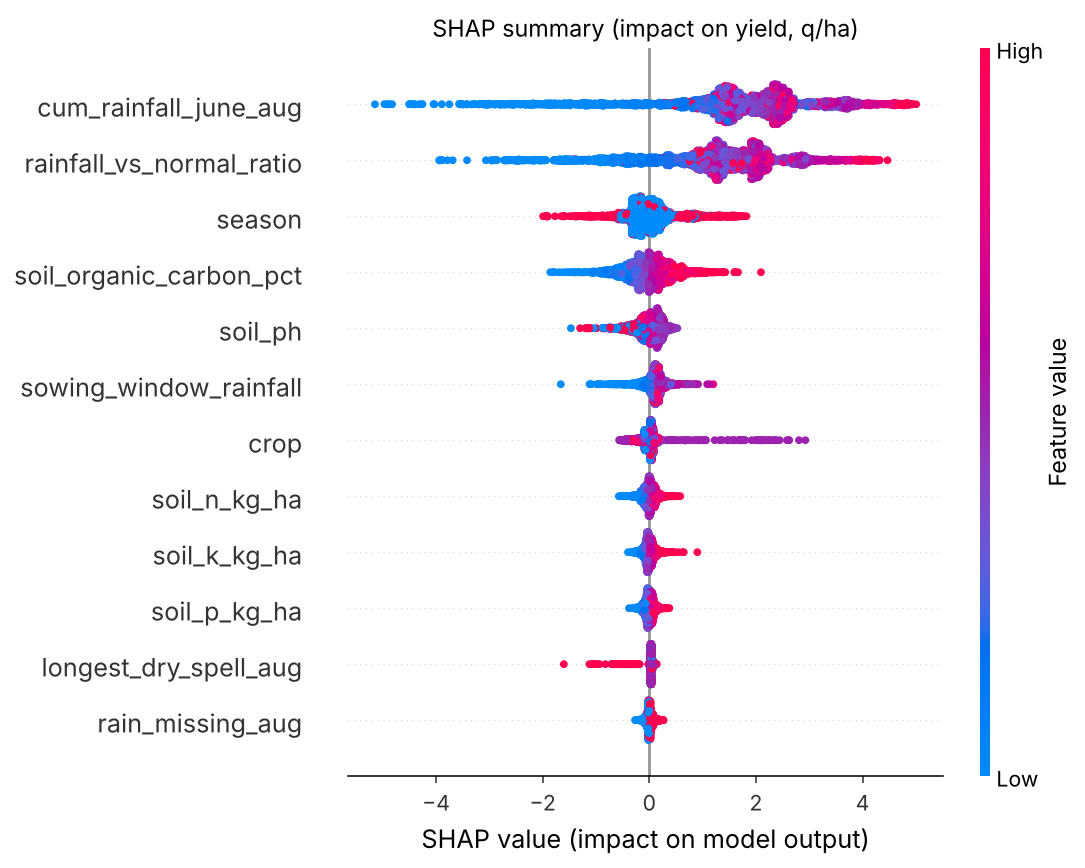

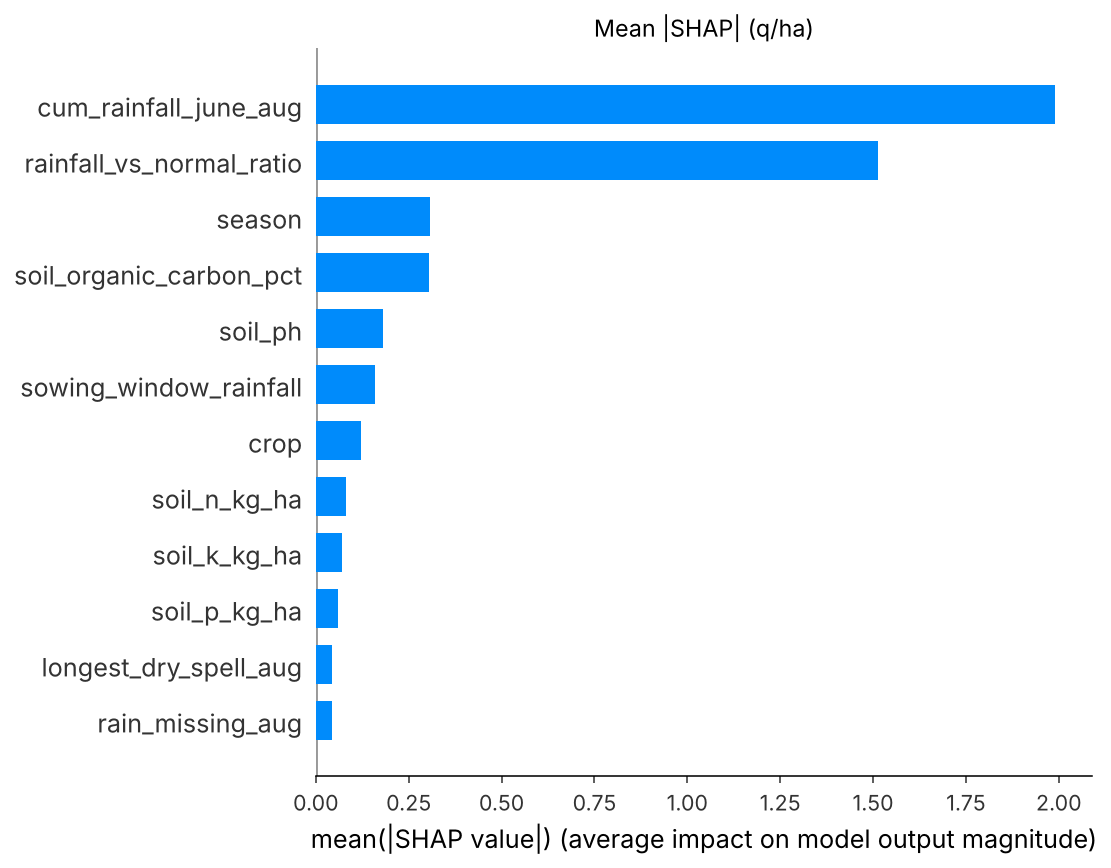

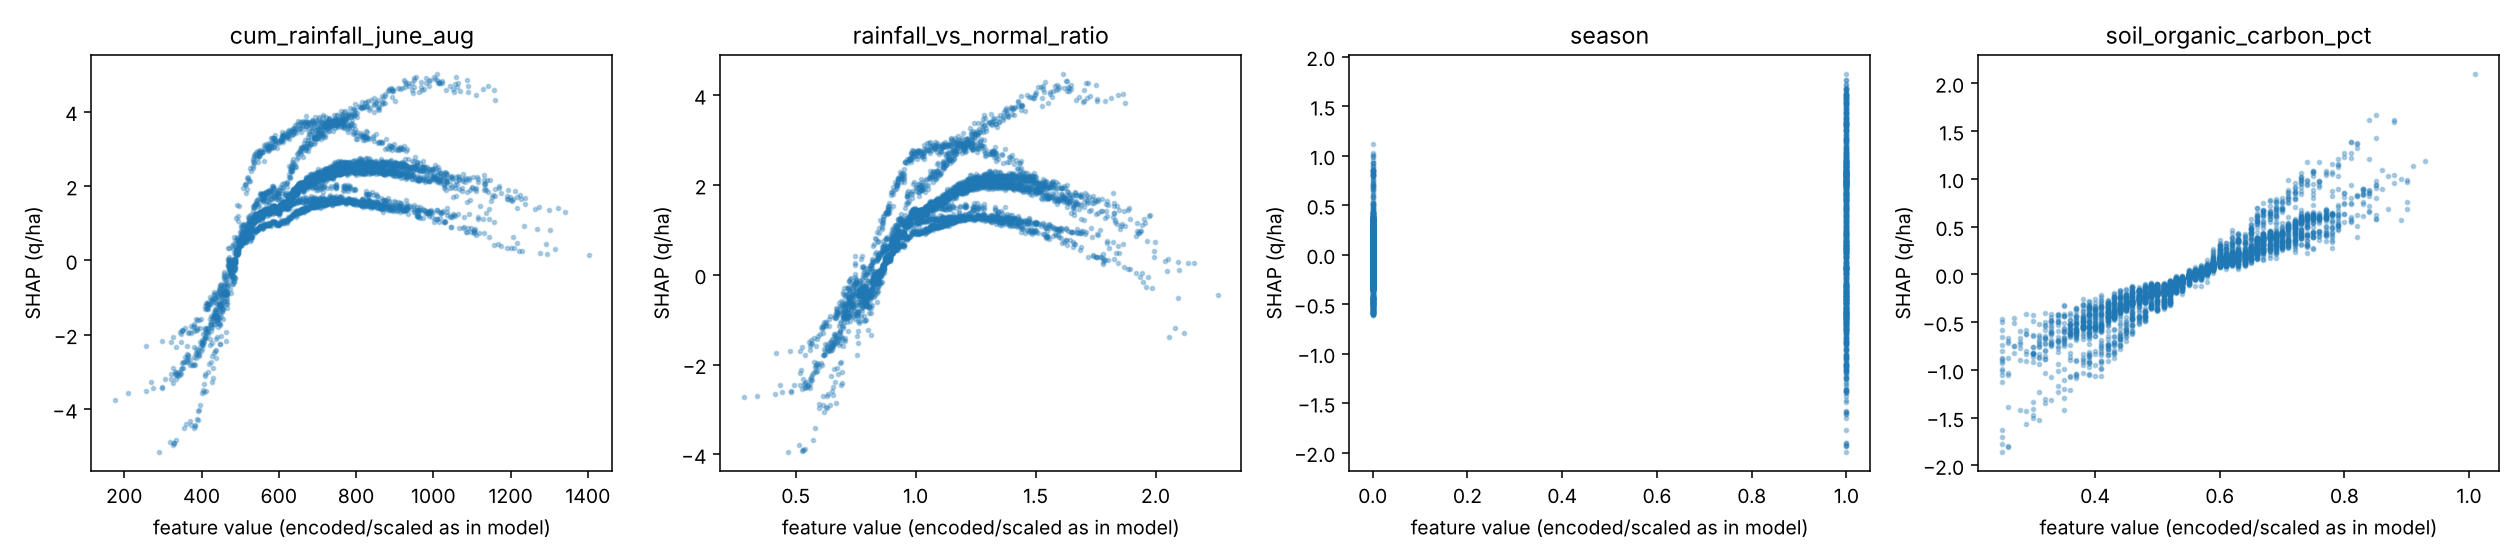

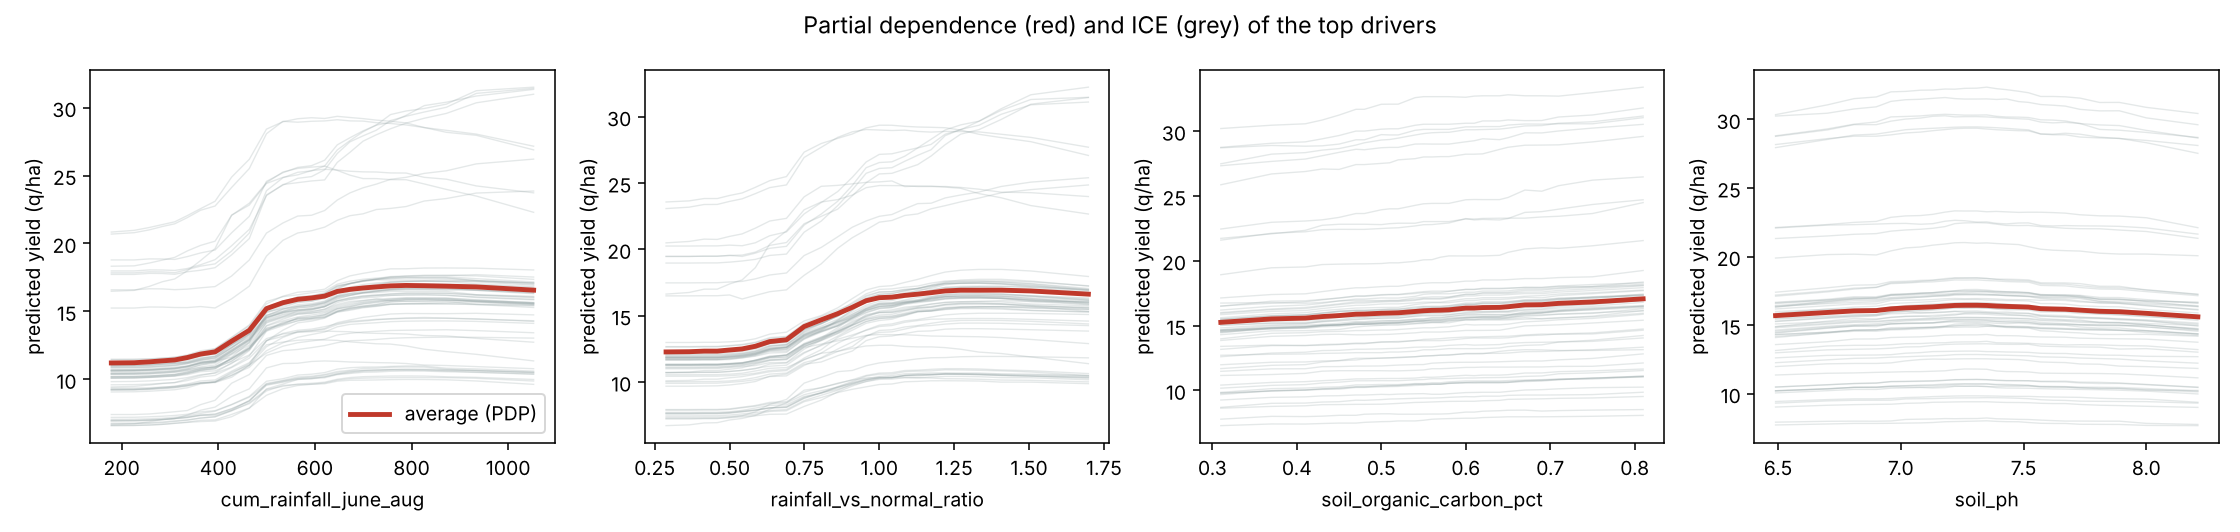

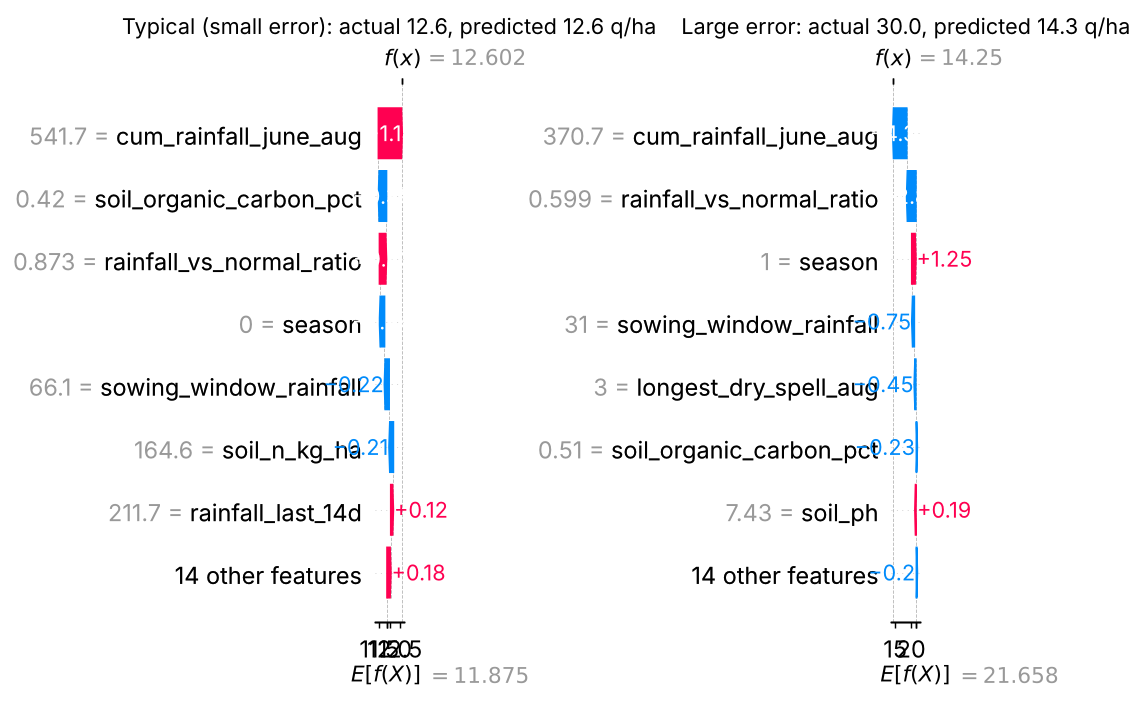

In [20]:
print(pd.DataFrame(E["shap_top_drivers"]).round(3).to_string(index=False))
for f in ["14_shap_summary.png", "14_shap_summary_and_bar.png", "15_shap_dependence_top_features.png", "16_pdp_ice_top_features.png", "17_shap_waterfall_examples.png"]:
    display(Image(filename=str(FIG_DIR / f), width=900))

In [21]:
DIR = {1: "raises", -1: "lowers"}
for d in E["shap_top_drivers"][:5]:
    side = DIR[int(np.sign(d["direction_spearman"]))] if abs(d["direction_spearman"]) > 0.3 else "has a weak/mixed effect on"
    print(f"- {d['feature']}: higher values {side} the forecast (mean |SHAP| {d['mean_abs_shap_q_ha']:.2f} q/ha; sensible = {d['sensible']})")

- cum_rainfall_june_aug: higher values raises the forecast (mean |SHAP| 1.99 q/ha; sensible = True)
- rainfall_vs_normal_ratio: higher values raises the forecast (mean |SHAP| 1.51 q/ha; sensible = True)
- season: higher values has a weak/mixed effect on the forecast (mean |SHAP| 0.31 q/ha; sensible = True)
- soil_organic_carbon_pct: higher values raises the forecast (mean |SHAP| 0.31 q/ha; sensible = True)
- soil_ph: higher values has a weak/mixed effect on the forecast (mean |SHAP| 0.18 q/ha; sensible = True)


**Plain English:** more cumulative monsoon rain, and rain closer to normal, raise the forecast; higher soil organic carbon raises it a little. `season` and `soil_ph` are weaker context features and should not be over-interpreted. In this synthetic world rainfall has two regimes (drought about 320 mm, normal about 700 mm), so rainfall dominates more than it would in reality.

---
# Section G: Procurement actions
Priority = forecast shortfall (tonnes) x price level. Intervals are split-conformal (90%), calibrated on validation seasons at district-crop-year level. The "drought" table is a **simulation**: weather of past drought years applied to 2024 records.

Conformal: {'level': 0.9, 'relative_half_width': 0.045770908116988765, 'n_calibration_groups': 126, 'test_group_coverage': 0.9682539682539683}
Assumptions: {'coverage_of_shortfall': 0.4, 'spot_premium': 0.15, 'note': 'Volumes are for the sampled farm records in the dataset, not whole-district production.'}
2024 forecast flags: {'NORMAL': 42} | simulated drought flags: {'HIGH': 42}

Top 10 pockets under simulated drought


,district,crop,pred_yield,normal_yield,change_vs_normal_pct,volume_t,lo_t,hi_t,shortfall_t,risk_flag,value_at_risk_rs_lakh
0,Yavatmal,cotton,6.96,15.56,-55.24,1946.15,1857.08,2035.23,2401.55,HIGH,261.49
1,Wardha,cotton,7.02,15.65,-55.13,1480.36,1412.60,1548.11,1818.91,HIGH,197.93
2,Amravati,cotton,6.94,15.57,-55.43,1402.25,1338.06,1466.43,1744.23,HIGH,189.79
3,Yavatmal,soybean,6.97,15.07,-53.76,1908.54,1821.19,1995.90,2219.08,HIGH,180.00
4,Amravati,soybean,6.68,14.96,-55.37,1678.15,1601.34,1754.96,2081.58,HIGH,168.83
5,Nagpur,cotton,6.98,15.75,-55.65,1150.49,1097.84,1203.15,1443.76,HIGH,157.19
6,Nagpur,soybean,6.72,15.00,-55.22,1528.34,1458.38,1598.29,1884.59,HIGH,152.89
7,Bhandara,rice,11.36,24.47,-53.58,2429.16,2317.98,2540.35,2803.68,HIGH,145.70
8,Wardha,soybean,6.82,14.92,-54.32,1461.59,1394.69,1528.49,1737.87,HIGH,140.90
9,Chandrapur,cotton,6.90,15.63,-55.84,853.95,814.86,893.03,1079.72,HIGH,117.59


2024 forecast, top 10 by priority


,district,crop,pred_yield,normal_yield,change_vs_normal_pct,volume_t,lo_t,hi_t,shortfall_t,risk_flag,value_at_risk_rs_lakh
0,Yavatmal,soybean,14.98,15.07,-0.62,4101.87,3914.13,4289.62,25.75,NORMAL,2.09
1,Nagpur,gram,11.98,12.20,-1.76,1067.13,1018.29,1115.98,19.15,NORMAL,1.50
2,Bhandara,cotton,15.25,15.76,-3.24,336.71,321.30,352.12,11.28,NORMAL,1.23
3,Bhandara,gram,11.84,12.05,-1.80,693.41,661.67,725.15,12.71,NORMAL,1.00
4,Chandrapur,wheat,27.03,27.26,-0.85,1488.64,1420.50,1556.77,12.77,NORMAL,0.60
5,Wardha,tur,9.90,9.95,-0.52,737.17,703.43,770.91,3.87,NORMAL,0.44
6,Nagpur,tur,10.03,10.06,-0.28,1160.77,1107.64,1213.90,3.31,NORMAL,0.38
7,Yavatmal,jowar,14.44,14.54,-0.64,507.91,484.66,531.15,3.27,NORMAL,0.14
8,Wardha,cotton,15.65,15.65,-0.04,3297.98,3147.03,3448.93,1.29,NORMAL,0.14
9,Yavatmal,wheat,27.03,27.07,-0.12,1759.26,1678.74,1839.79,2.17,NORMAL,0.10


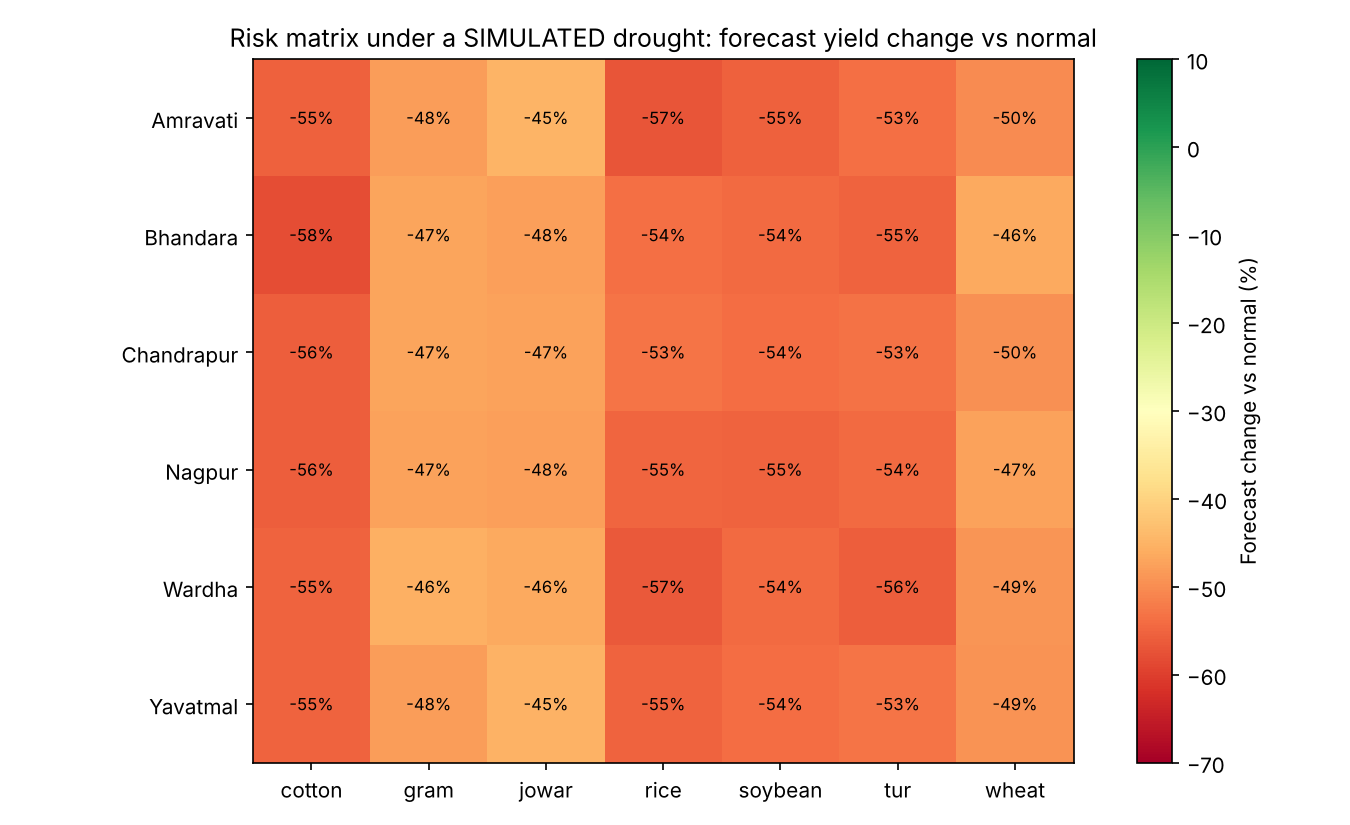

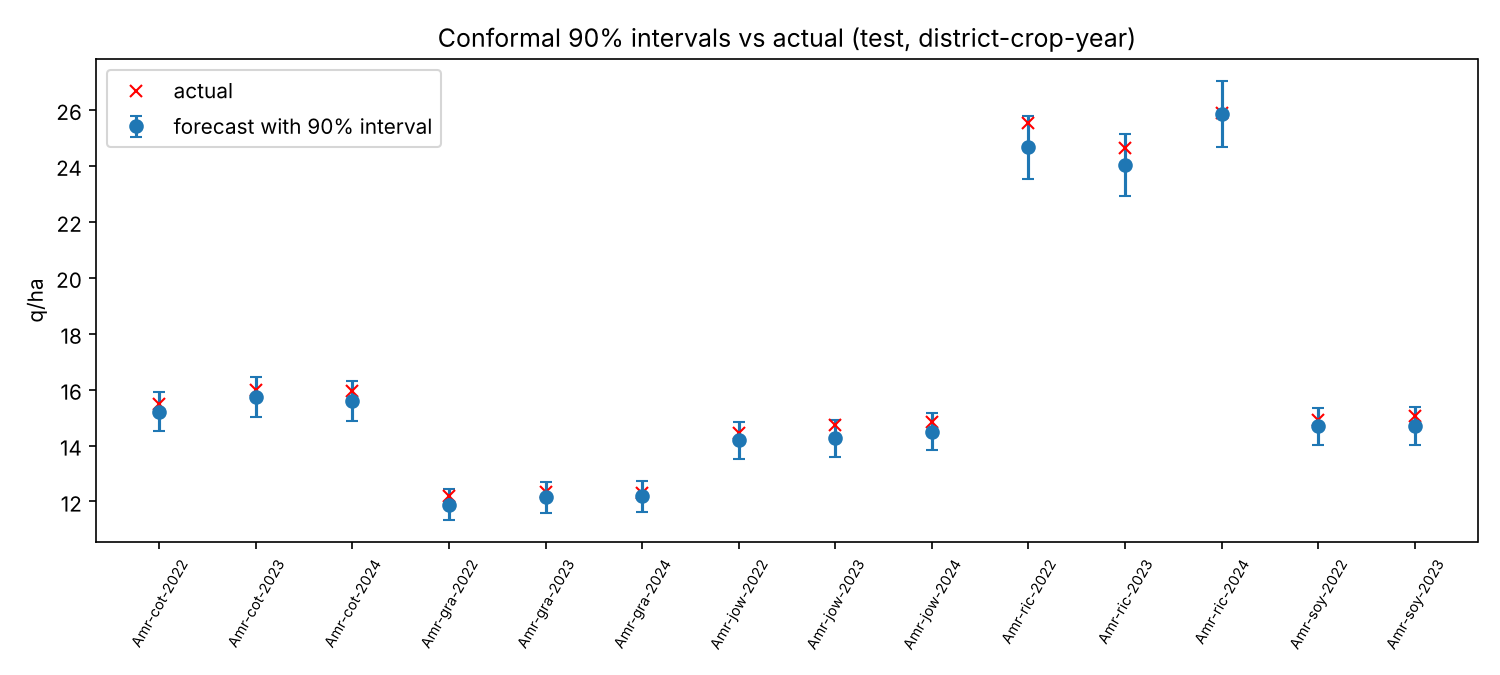

In [22]:
print("Conformal:", P["conformal"]); print("Assumptions:", P["assumptions"])
print("2024 forecast flags:", P["plan_2024_flags"], "| simulated drought flags:", P["plan_drought_flags"])
print("\nTop 10 pockets under simulated drought")
display(pd.DataFrame(P["plan_drought_top10"]))
print("2024 forecast, top 10 by priority")
display(pd.DataFrame(P["plan_2024_top10"]))
display(Image(filename=str(FIG_DIR / "18_procurement_risk_matrix.png"), width=700))
display(Image(filename=str(FIG_DIR / "21_conformal_uncertainty_bands.png"), width=800))

In [23]:
print(f"Simulated drought: total shortfall {P['drought_total_shortfall_t']:,.0f} t; early contracts secure {P['drought_tonnes_secured']:,.0f} t under the stated coverage assumption")
display(pd.DataFrame(P["crop_ranking_drought"])); display(pd.DataFrame(P["district_ranking_drought"]))

Simulated drought: total shortfall 34,960 t; early contracts secure 13,984 t under the stated coverage assumption


,crop,shortfall_t,mean_change_pct
0,soybean,9435.3,-54.5
1,cotton,8690.2,-55.9
2,rice,5511.4,-55.0
3,wheat,4956.4,-48.6
4,tur,2864.1,-54.1
5,gram,2272.3,-47.2
6,jowar,1230.7,-46.5


,district,shortfall_t,mean_change_pct
0,Nagpur,7040.9,-51.8
1,Yavatmal,6732.3,-51.3
2,Amravati,6142.2,-52.0
3,Wardha,5263.2,-51.8
4,Chandrapur,4974.1,-51.4
5,Bhandara,4807.7,-51.7


**Actions:** (1) keep normal contracting where the forecast is near normal; (2) if weather signals a drought, secure supply first in the largest pockets, ranked above; (3) do not over-commit forward sales for any pocket forecast below 85% of normal; (4) prices rise about 13% in drought years in this data, so early contracts avoid spot premiums.

---
# Section H: Fairness, stability and recalibration

Overall MAE 1.505, overall MAPE 9.60%


,group_type,group,n,mae,mape_pct,bias_q_ha,bias_pct,flag_abs_mae,flag_rel_error,flag_bias
0,district,Amravati,9873,1.39,9.59,-0.27,-1.75,False,False,False
1,district,Bhandara,6373,1.87,9.91,-0.24,-1.22,True,False,False
2,district,Chandrapur,7597,1.59,9.58,-0.24,-1.40,False,False,False
3,district,Nagpur,10879,1.52,9.52,-0.28,-1.70,False,False,False
4,district,Wardha,8790,1.38,9.36,-0.24,-1.53,False,False,False
5,district,Yavatmal,10921,1.42,9.71,-0.24,-1.57,False,False,False
6,crop,cotton,13511,1.45,9.78,-0.24,-1.51,False,False,False
7,crop,gram,5259,1.09,9.12,-0.28,-2.32,False,False,False
8,crop,jowar,2358,1.32,9.23,-0.22,-1.53,False,False,False
9,crop,rice,5821,2.44,10.54,-0.26,-1.05,True,False,False


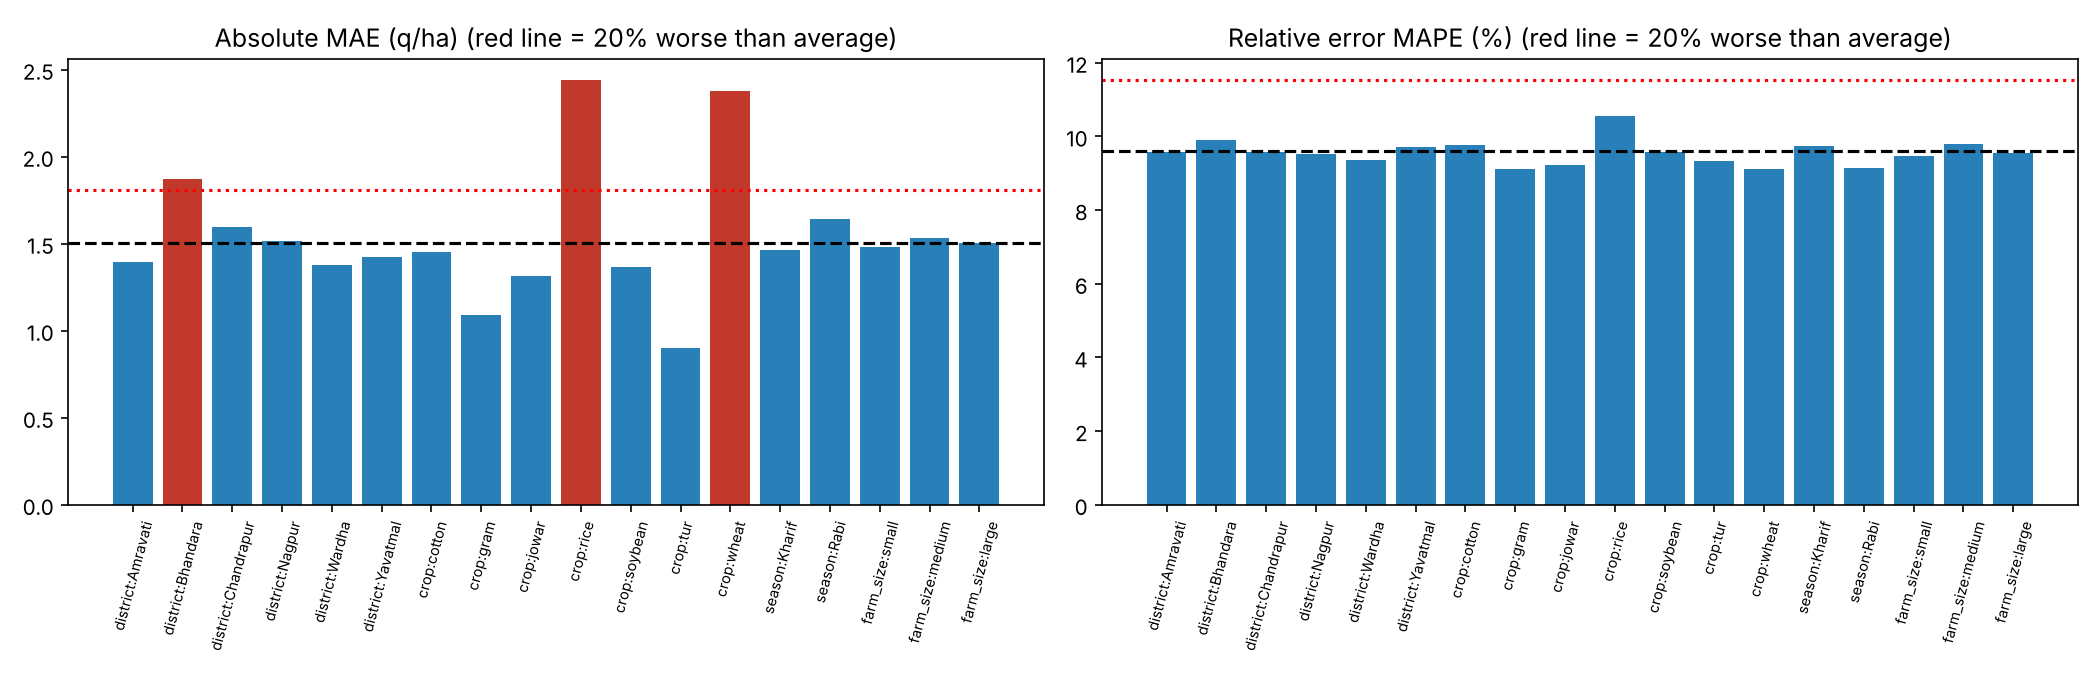

In [24]:
ft = pd.DataFrame(P["fairness"]["table"]).round(2)
print("Overall MAE %.3f, overall MAPE %.2f%%" % (P["fairness"]["overall_mae"], P["fairness"]["overall_mape_pct"]))
display(ft)
display(Image(filename=str(FIG_DIR / "19_fairness_subgroup_disparity.png"), width=900))

Test MAE by year: {'2022': 1.489, '2023': 1.519, '2024': 1.506}
Bootstrap 95% CI of test MAE: [1.494, 1.517]
50% of rain readings removed: MAE 1.564 (+3.9%) | 10% rain noise: 1.567 (+4.2%)


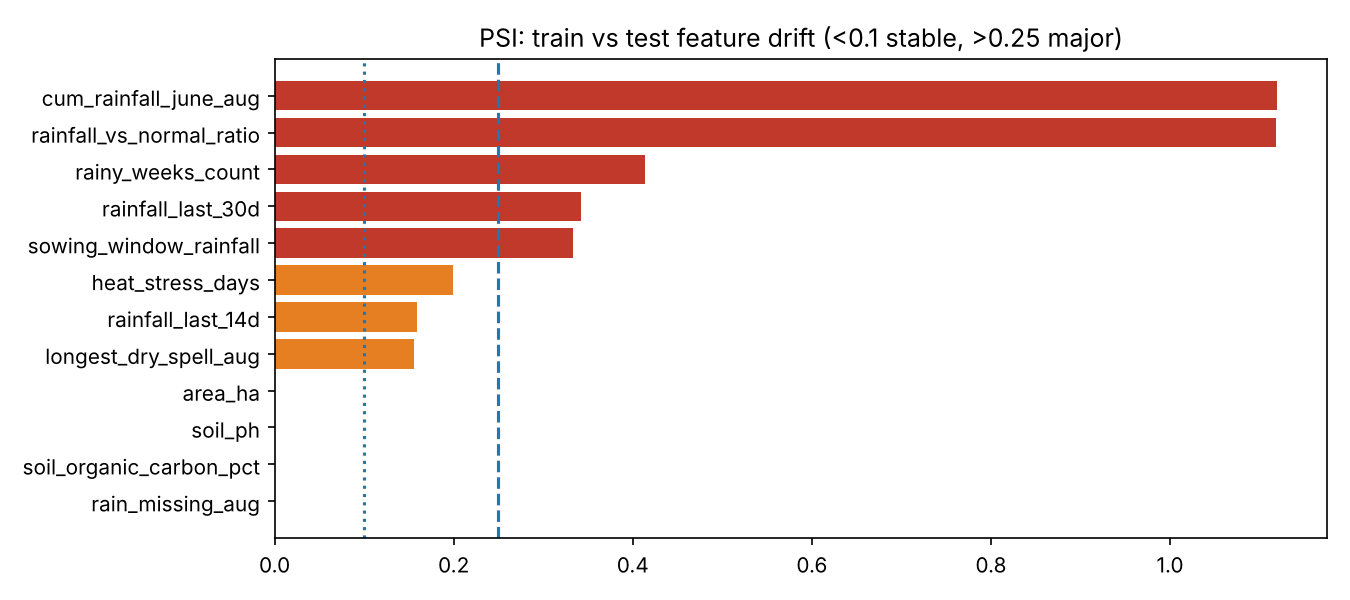

Recalibration (fit on validation, judged on test): {'before_mae': 1.5047, 'linear_mae': 1.5034, 'isotonic_mae': 1.466, 'linear_coef': [1.2186864295221511, 0.9459471196791197], 'before_bias': -0.255, 'linear_bias': 0.0869, 'linear_change_pct': -0.0828, 'isotonic_change_pct': -2.5672, 'adopt_recalibration': True}


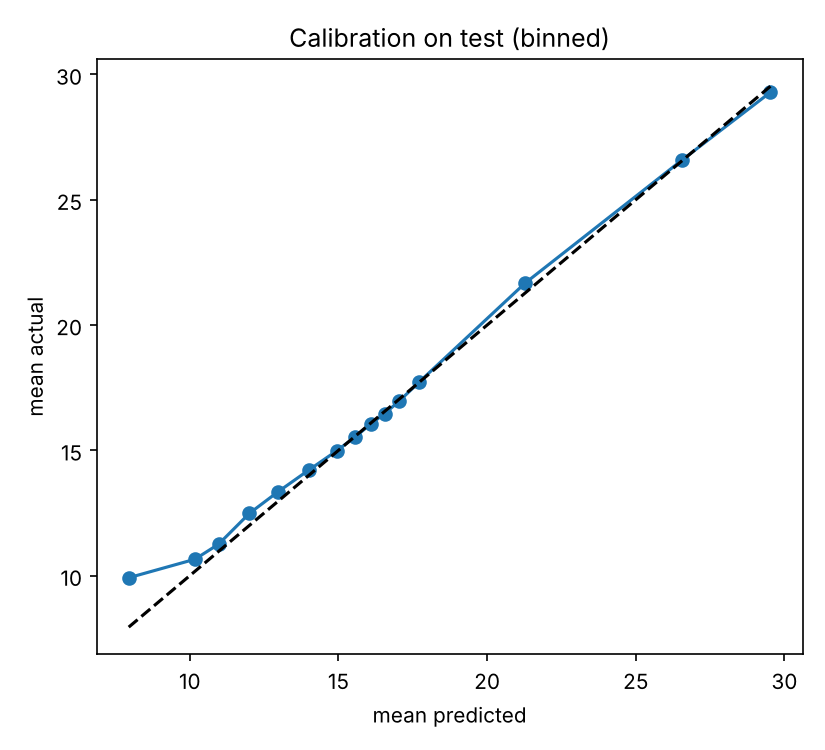

In [25]:
st = P["stability"]
print("Test MAE by year:", {k: round(v, 3) for k, v in st["by_year"].items()})
print("Bootstrap 95% CI of test MAE:", [round(x, 3) for x in st["bootstrap_mae_ci95"]])
print(f"50% of rain readings removed: MAE {st['mae_50pct_rain_missing']:.3f} ({st['mae_change_missing_pct']:+.1f}%) | 10% rain noise: {st['mae_10pct_rain_noise']:.3f} ({st['mae_change_noise_pct']:+.1f}%)")
display(Image(filename=str(FIG_DIR / "20_psi_feature_drift.png"), width=700))
print("Recalibration (fit on validation, judged on test):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in P["recalibration"].items()})
display(Image(filename=str(FIG_DIR / "22_calibration_curve.png"), width=450))

**Reading:** relative error is within 20% of average everywhere; the groups flagged on absolute MAE (high-yield crops and districts) are not worse in percentage terms. All groups are slightly under-predicted. PSI is large for rainfall because the training period contains droughts and the test period does not (a regime difference). Isotonic recalibration helps a little and is recommended for deployment but is not baked into the saved model.

---
# Section I: One wrong prediction

# Case Study: One Large Error in the Test Period (2022-2024)

> Data in this project is **synthetic**. The record below is a real row of the generated test set; all numbers are computed by `src/case_study.py`.

**Record:** `REC_0340473` | YTL_DARWHA_003, Yavatmal | rice | season 2023

## 1. Predicted vs actual
| | q/ha |
|---|---:|
| Actual yield (cleaned) | **4.70** |
| Model forecast (as of 31 Aug) | **31.00** |
| Error | **+26.30** (+560% of actual) -> over-predicted |
| Historical normal for this district-crop (anchor) | 24.27 |
| Naive last-year baseline | 25.47 |
| Average abs. error on the whole test set | 1.50 |

This is the single worst of 54,433 test predictions, i.e. 17.5x the typical error.

## 2. What the model saw (SHAP waterfall)
![SHAP waterfall](figures/23_case_study_shap_waterfall.png)

Largest contributions (q/ha, relative to the model's average of 19.67):
- `cum_rainfall_june_aug` = 940.40 (scaled/encoded value): **+4.65 q/ha**
- `rainfall_vs_normal_ratio` = 1.52 (scaled/encoded value): **+4.13 q/ha**
- `crop` = 3.00 (scaled/encoded value): **+1.62 q/ha**
- `season` = 0.00 (scaled/encoded value): **+0.67 q/ha**
- `soil_ph` = 6.71 (scaled/encoded value): **-0.42 q/ha**

Reading: the model starts from the district-crop normal of 24.3 q/ha and adjusts using rainfall, soil and crop features. For this record the inputs looked ordinary (rainfall at or above normal: 940 mm, ratio 1.52; longest dry spell 1 weeks; organic carbon 0.64%), so the model predicted a normal yield.

## 3. Was it a data problem, an unusual event, or a model limitation?
- **Data problem (cleaning error).** The raw yield was 470.0. The cleaning rule read it as kg/ha and divided by 100, giving 4.7 q/ha. The ground-truth log shows this row had NO kg/ha unit error: 400-950 values were injected as extreme outliers, and this one overlaps the range where kg/ha and an outlier look alike. The 'corrected' label is therefore wrong, and the model's forecast of 31.0 q/ha (close to the district-crop normal of 24.3) was actually sensible. Across the test set 68 rows (0.12%) were wrongly unit-fixed; test MAE is 1.505 on all rows and 1.496 when they are excluded.
- Part of the June-August rainfall was missing and imputed, so the weather features for this record are estimates.

Raw input check: raw yield in file = 470.0, unit-fix = kg_to_quintal, missing rainfall weeks = 1. Share of all test records that were unit-fixed: 5.13%.

## 4. What we would change
1. **Fix the cleaning rule**: do not auto-convert values that are ambiguous between 'kg/ha' and 'outlier'; flag them for review (and exclude from training/evaluation) instead.
2. Re-run the unit-fix accuracy check against the ground-truth log after every cleaning change.
3. Report forecasts as intervals and aggregate to district-crop level for procurement, where single bad labels average out.

## 2-minute talk track
"Our worst test miss: the model said 31.0 q/ha for a rice field in Yavatmal, the record said 4.7. When I traced it, the model was fine: the raw yield was 470.0, an extreme outlier that my unit-fix rule wrongly divided by 100. It is a cleaning error, 68 test rows are affected, and the fix is to flag values that fit both a kg/ha and an outlier reading instead of auto-converting them."


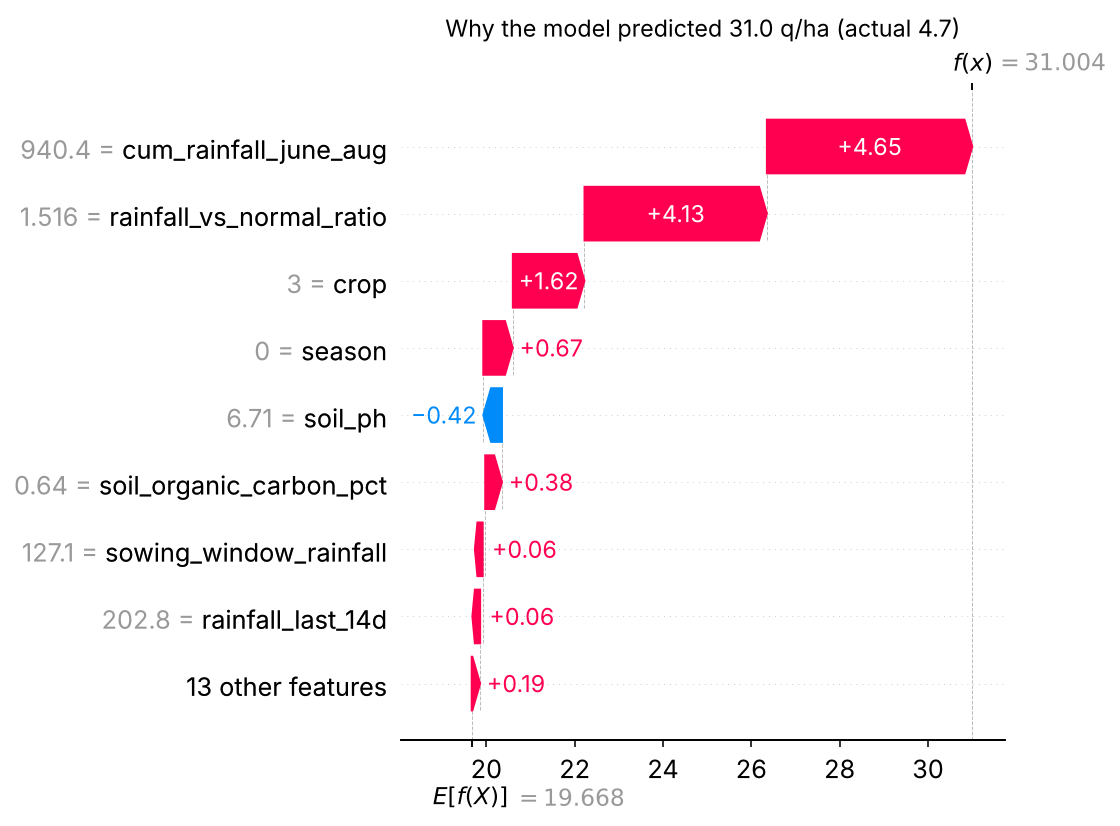

In [26]:
display(Markdown((REP / "wrong_prediction_case_study.md").read_text(encoding="utf-8").replace("figures/", str(FIG_DIR.relative_to(PROJECT_ROOT)).replace("reports/", "") + "/")))
display(Image(filename=str(FIG_DIR / "23_case_study_shap_waterfall.png"), width=700))

---
# Section J: Limitations and next steps
1. Synthetic data with simple weather regimes; real data will be harder.
2. The cleaning rule wrongly divided some extreme outliers by 100 (kg/ha precision below 100%); the worst test error came from this. Fix: flag ambiguous values instead of converting.
3. Three drought seasons only; the drought procurement table is a simulation.
4. Add recalibration to the deployed pipeline; monitor MAE by group, bias and PSI monthly; re-train each season.